# 09 Analysis: WRPC ancillary services, CY2025 and CY2026 to August

Organised around five questions. Reads only the step 08 outputs in `data/processed/`, the station master
(`docs/reference/station_master.csv`) and, for question 4 only, the step 02, 05 and 07 interim outputs.
Every chart is saved to `outputs/figures/` and every summary table to `outputs/tables/` (prefix `09_`).
Money is in **₹ crore** (₹1 crore = ₹10,000,000); **+ = payable from the pool to providers** (the generators receive),
**− = receivable by the pool**.

## Section 0: Setup and caveats

In [1]:
from pathlib import Path
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd()
while not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import config  # noqa: E402

FIG, TAB = config.FIGURES_DIR, config.TABLES_DIR
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
CRORE = 1e7
TOTAL = "total_net_payable_from_pool_to_providers_crore"
PERIOD = {2025: "CY2025", 2026: "CY2026 to Aug"}
COMBINED_END = pd.Timestamp("2025-05-12")  # last combined-layout week (Shortfall and Emergency not separable)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

KEY = []  # headline numbers, collected per question


def key(question, metric, value, unit, source):
    KEY.append({"question": question, "metric": metric, "value": value, "unit": unit, "source": source})


def save_fig(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()
    return f"outputs/figures/{name}"


def save_tab(df, name, index=False):
    df.to_csv(TAB / name, index=index)
    return f"outputs/tables/{name}"


def facts(lines):
    display(Markdown("\n".join(f"- {l}" for l in lines)))


def cr(x):
    return f"₹{x:,.2f} crore"

In [2]:
weekly = pd.read_csv(config.WEEKLY_SUMMARY_CSV, parse_dates=["week_start", "week_end"])
weekly["period"] = weekly["iso_year"].map(PERIOD)
facts_df = pd.read_csv(config.FACTS_CSV, parse_dates=["week_start"], low_memory=False)
facts_df["period"] = facts_df["iso_year"].map(PERIOD)
perf = pd.read_csv(config.SRAS_PERFORMANCE_DAILY_CSV, parse_dates=["date", "week_start"])
master = pd.read_csv(config.STATION_MASTER_CSV, keep_default_na=False)
print(f"weeks: {len(weekly)} ({weekly['week_start'].min():%Y-%m-%d} to {weekly['week_start'].max():%Y-%m-%d}); "
      f"facts: {len(facts_df):,}; SRAS performance rows: {len(perf):,}; stations: {len(master)}, plants: {master['plant_id'].nunique()}")

# Check against the step 08 summary; stop if the totals differ.
EXPECTED = {"CY2025": 3620.55, "CY2026 to Aug": 1786.57}
totals = weekly.groupby("period")[TOTAL].sum().round(2)
print(totals.to_string())
for p, v in EXPECTED.items():
    assert totals[p] == v, f"{p}: total {totals[p]} != step 08 summary {v}"
assert len(weekly) == config.EXPECTED_WEEKS and weekly["week_start"].is_unique

weeks: 87 (2024-12-30 to 2026-08-24); facts: 98,073; SRAS performance rows: 10,962; stations: 132, plants: 122
period
CY2025           3620.55
CY2026 to Aug    1786.57


**Data caveats**

- **As of the fetch date.** The data is as published on the WRPC website when the file lists were fetched
  (step 01 snapshots). Later revisions are not included.
- **Shortfall vs Emergency.** These are available separately only for weeks from **2025-05-19**. Before that, the
  statements have one combined Shortfall/Emergency table (`TRAS_III_COMBINED`), which cannot be split (A11).
  `TRAS_III_TOTAL` is consistent across all 87 weeks.
- **Thursday rule.** Weeks are assigned to years and months by the year or month containing their Thursday (A01).
  CY2025 = 52 weeks (2024-12-30 to 2025-12-28); CY2026 to Aug = 35 weeks (2025-12-29 to 2026-08-30).
- **A15.** A station absent from a section table is treated as having zero charges for that section, when its own
  consolidated table shows 0.
- **A18.** Two June 2026 TRAS overlay tables headed "Shortfall Condition" but with "Emergency" column labels are
  treated as Shortfall.
- **SRAS performance above 100%.** 151 published daily values in the selected data are above 100%. They are kept as
  published and flagged.

## Q1. How much did ancillary services cost, and how did it change over time?

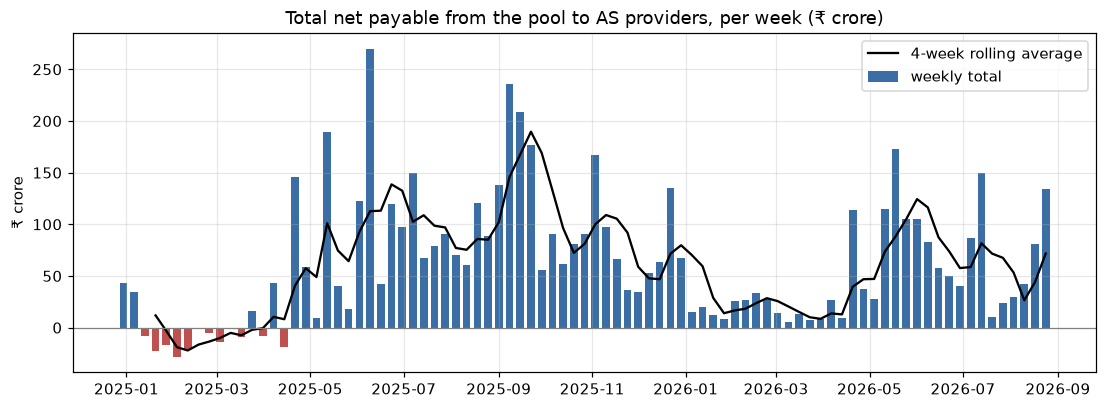

In [3]:
q1 = weekly[["week_start", "period", "month", TOTAL]].copy()
q1["rolling_4wk"] = q1[TOTAL].rolling(4).mean()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(q1["week_start"], q1[TOTAL], width=5, color=np.where(q1[TOTAL] >= 0, "#3b6ea5", "#c0504d"), label="weekly total")
ax.plot(q1["week_start"], q1["rolling_4wk"], color="black", lw=1.5, label="4-week rolling average")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Total net payable from the pool to AS providers, per week (₹ crore)")
ax.set_ylabel("₹ crore")
ax.legend()
F_Q1_WEEKLY = save_fig(fig, "09_q1_weekly_total.png")
T_Q1_WEEKLY = save_tab(q1, "09_q1_weekly_total.csv")

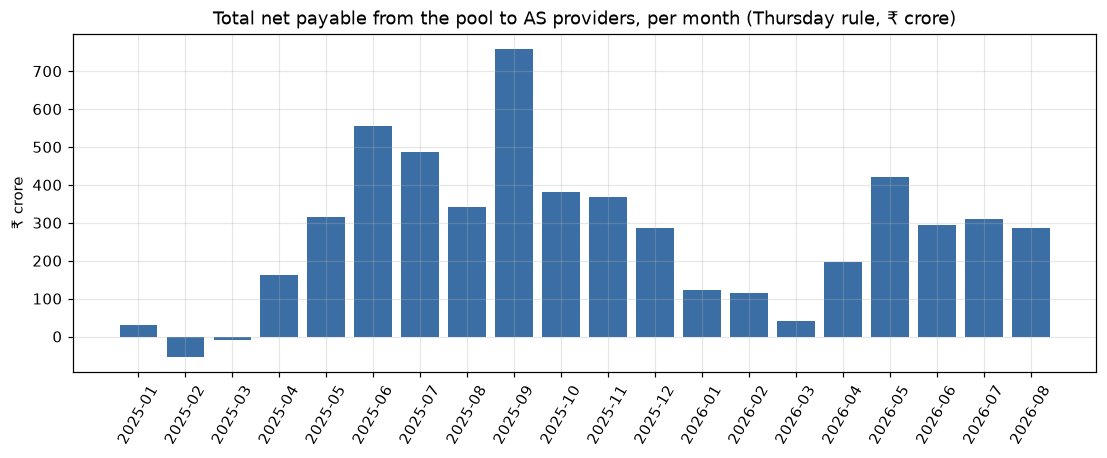

,month,total_crore,weeks
0,2025-01,30.429115,5
1,2025-02,-53.947649,4
2,2025-03,-8.320715,4
3,2025-04,162.576592,4
4,2025-05,316.469677,5
5,2025-06,554.639395,4
6,2025-07,485.623081,5
7,2025-08,340.413252,4
8,2025-09,758.513223,4
9,2025-10,380.237915,5


In [4]:
monthly = weekly.groupby("month")[TOTAL].agg(total_crore="sum", weeks="size").reset_index()
T_Q1_MONTHLY = save_tab(monthly, "09_q1_monthly_totals.csv")
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(monthly["month"], monthly["total_crore"], color="#3b6ea5")
ax.set_title("Total net payable from the pool to AS providers, per month (Thursday rule, ₹ crore)")
ax.set_ylabel("₹ crore")
ax.tick_params(axis="x", rotation=60)
F_Q1_MONTHLY = save_fig(fig, "09_q1_monthly_totals.png")
monthly

In [5]:
years = weekly.groupby("period")[TOTAL].agg(weeks="size", total_crore="sum", weekly_average_crore="mean",
                                            weekly_median_crore="median", weekly_min_crore="min",
                                            weekly_max_crore="max").reset_index()
years["weeks_pool_paid_out"] = weekly.groupby("period")[TOTAL].apply(lambda s: int((s > 0).sum())).values
years["weeks_pool_received"] = weekly.groupby("period")[TOTAL].apply(lambda s: int((s < 0).sum())).values
T_Q1_YEARS = save_tab(years, "09_q1_year_comparison.csv")
years

,period,weeks,total_crore,weekly_average_crore,weekly_median_crore,weekly_min_crore,weekly_max_crore,weeks_pool_paid_out,weeks_pool_received
0,CY2025,52,3620.545302,69.625871,61.257723,-28.057519,270.027923,40,12
1,CY2026 to Aug,35,1786.565730,51.044735,29.761804,5.785050,173.298279,35,0


In [6]:
mech_cols = ["SRAS_net_crore", "TRAS_III_TOTAL_net_crore", "TRAS_MARKET_DAM_net_crore", "TRAS_MARKET_RTM_net_crore", "SCUC_net_crore"]
ranked = weekly[["week_start", "period", TOTAL] + mech_cols].sort_values(TOTAL, ascending=False)
top10 = ranked.head(10).assign(rank="highest")
bottom10 = ranked.tail(10).sort_values(TOTAL).assign(rank="lowest")
T_Q1_TOPBOTTOM = save_tab(pd.concat([top10, bottom10]), "09_q1_highest_lowest_weeks.csv")
pd.concat([top10, bottom10]).round(2)

/var/folders/j9/9p21ns8d687dr8fy_qzgt8mc0000gn/T/ipykernel_74481/1592015623.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  pd.concat([top10, bottom10]).round(2)


,week_start,period,total_net_payable_from_pool_to_providers_crore,SRAS_net_crore,TRAS_III_TOTAL_net_crore,TRAS_MARKET_DAM_net_crore,TRAS_MARKET_RTM_net_crore,SCUC_net_crore,rank
23,2025-06-09,CY2025,270.03,-0.79,29.16,-0.05,-0.01,241.72,highest
36,2025-09-08,CY2025,235.97,0.88,19.09,-0.05,-0.14,216.19,highest
37,2025-09-15,CY2025,208.26,1.22,-0.43,-0.05,-0.19,207.71,highest
19,2025-05-12,CY2025,189.45,0.33,-12.99,-0.02,0.00,202.12,highest
38,2025-09-22,CY2025,176.35,2.43,-8.21,-0.08,0.54,181.67,highest
72,2026-05-18,CY2026 to Aug,173.30,-1.01,23.95,-0.07,0.87,149.56,highest
44,2025-11-03,CY2025,167.02,3.89,-2.31,-0.08,1.01,164.50,highest
27,2025-07-07,CY2025,149.97,-1.98,7.70,-0.05,-0.02,144.31,highest
80,2026-07-13,CY2026 to Aug,149.53,-1.15,41.47,-0.04,-0.25,109.50,highest
16,2025-04-21,CY2025,146.21,-1.89,15.55,-0.01,0.00,132.56,highest


### What the data shows

In [7]:
y = years.set_index("period")
hi, lo = top10.iloc[0], bottom10.iloc[0]
paid_out, received = int((weekly[TOTAL] > 0).sum()), int((weekly[TOTAL] < 0).sum())
mmax, mmin = monthly.loc[monthly["total_crore"].idxmax()], monthly.loc[monthly["total_crore"].idxmin()]
facts([
    f"Total net payable from the pool to AS providers: CY2025 {cr(y.at['CY2025', 'total_crore'])} over 52 weeks; "
    f"CY2026 to Aug {cr(y.at['CY2026 to Aug', 'total_crore'])} over 35 weeks ({T_Q1_YEARS}).",
    f"Weekly average: CY2025 {cr(y.at['CY2025', 'weekly_average_crore'])}; CY2026 to Aug "
    f"{cr(y.at['CY2026 to Aug', 'weekly_average_crore'])} ({T_Q1_YEARS}).",
    f"Highest week: {hi['week_start']:%Y-%m-%d}, {cr(hi[TOTAL])}; lowest week: {lo['week_start']:%Y-%m-%d}, "
    f"{cr(lo[TOTAL])} ({T_Q1_TOPBOTTOM}).",
    f"The pool paid out (total > 0) in {paid_out} of 87 weeks and received (total < 0) in {received} ({T_Q1_YEARS}).",
    f"Highest month: {mmax['month']} ({cr(mmax['total_crore'])}); lowest month: {mmin['month']} "
    f"({cr(mmin['total_crore'])}) ({T_Q1_MONTHLY}, {F_Q1_MONTHLY}).",
])
key("Q1", "Total net payable from pool, CY2025", round(y.at["CY2025", "total_crore"], 2), "₹ crore", T_Q1_YEARS)
key("Q1", "Total net payable from pool, CY2026 to Aug", round(y.at["CY2026 to Aug", "total_crore"], 2), "₹ crore", T_Q1_YEARS)
key("Q1", "Weekly average, CY2025", round(y.at["CY2025", "weekly_average_crore"], 2), "₹ crore/week", T_Q1_YEARS)
key("Q1", "Weekly average, CY2026 to Aug", round(y.at["CY2026 to Aug", "weekly_average_crore"], 2), "₹ crore/week", T_Q1_YEARS)
key("Q1", f"Highest week ({hi['week_start']:%Y-%m-%d})", round(hi[TOTAL], 2), "₹ crore", T_Q1_TOPBOTTOM)
key("Q1", "Weeks the pool paid out / received", f"{paid_out} / {received}", "weeks", T_Q1_YEARS)

- Total net payable from the pool to AS providers: CY2025 ₹3,620.55 crore over 52 weeks; CY2026 to Aug ₹1,786.57 crore over 35 weeks (outputs/tables/09_q1_year_comparison.csv).
- Weekly average: CY2025 ₹69.63 crore; CY2026 to Aug ₹51.04 crore (outputs/tables/09_q1_year_comparison.csv).
- Highest week: 2025-06-09, ₹270.03 crore; lowest week: 2025-02-03, ₹-28.06 crore (outputs/tables/09_q1_highest_lowest_weeks.csv).
- The pool paid out (total > 0) in 75 of 87 weeks and received (total < 0) in 12 (outputs/tables/09_q1_year_comparison.csv).
- Highest month: 2025-09 (₹758.51 crore); lowest month: 2025-02 (₹-53.95 crore) (outputs/tables/09_q1_monthly_totals.csv, outputs/figures/09_q1_monthly_totals.png).

### Questions to interpret

- Why is the weekly average lower in CY2026 to Aug than in CY2025 (see `09_q1_year_comparison.csv`)?
- What happened in the highest weeks (2025-06-09, and the September 2025 weeks) and in the 12 weeks when the pool
  received money overall (`09_q1_highest_lowest_weeks.csv`)?
- Why is February 2025 the only clearly negative month, and September 2025 the highest (`09_q1_monthly_totals.png`)?
- Is there a seasonal pattern in the weekly series, and does the 4-week average show a trend (`09_q1_weekly_total.png`)?

## Q2. Which mechanism drives the cost?

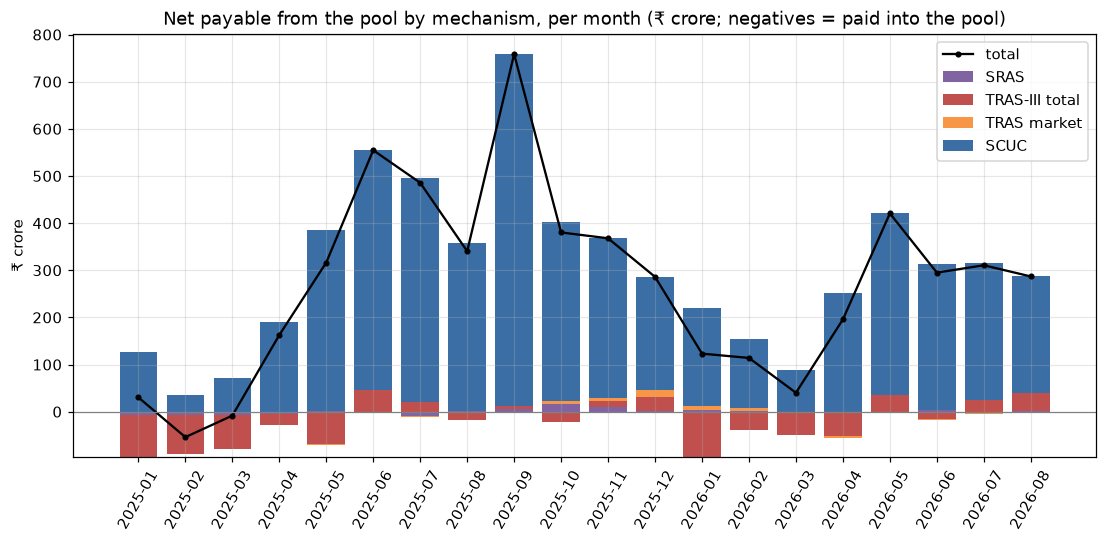

,CY2025,CY2026 to Aug,CY2025 share of total net,CY2026 to Aug share of total net
SRAS,5.714,6.117,0.002,0.003
TRAS-III total,-262.539,-151.779,-0.073,-0.085
TRAS market,27.680,3.640,0.008,0.002
SCUC,3849.689,1928.587,1.063,1.079


In [8]:
MECH = {"SRAS": weekly["SRAS_net_crore"], "TRAS-III total": weekly["TRAS_III_TOTAL_net_crore"],
        "TRAS market": weekly["TRAS_MARKET_DAM_net_crore"] + weekly["TRAS_MARKET_RTM_net_crore"],
        "SCUC": weekly["SCUC_net_crore"]}
by_mech = pd.DataFrame(MECH).assign(month=weekly["month"], period=weekly["period"])
monthly_mech = by_mech.groupby("month")[list(MECH)].sum()
T_Q2_MONTHLY = save_tab(monthly_mech.reset_index(), "09_q2_monthly_by_mechanism.csv")
colors = {"SRAS": "#8064a2", "TRAS-III total": "#c0504d", "TRAS market": "#f79646", "SCUC": "#3b6ea5"}
fig, ax = plt.subplots(figsize=(12, 5))
pos_bottom = np.zeros(len(monthly_mech)); neg_bottom = np.zeros(len(monthly_mech))
for m in MECH:
    v = monthly_mech[m].values
    ax.bar(monthly_mech.index, np.where(v > 0, v, 0), bottom=pos_bottom, color=colors[m], label=m)
    ax.bar(monthly_mech.index, np.where(v < 0, v, 0), bottom=neg_bottom, color=colors[m])
    pos_bottom += np.where(v > 0, v, 0); neg_bottom += np.where(v < 0, v, 0)
ax.plot(monthly_mech.index, monthly_mech.sum(axis=1), "k.-", label="total")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Net payable from the pool by mechanism, per month (₹ crore; negatives = paid into the pool)")
ax.set_ylabel("₹ crore"); ax.tick_params(axis="x", rotation=60); ax.legend()
F_Q2_MONTHLY = save_fig(fig, "09_q2_monthly_by_mechanism.png")

share = by_mech.groupby("period")[list(MECH)].sum().T
share.columns.name = None
for p in list(share.columns):
    share[f"{p} share of total net"] = share[p] / share[p].sum()
T_Q2_SHARE = save_tab(share.reset_index(names="mechanism"), "09_q2_mechanism_share_by_year.csv")
share.round(3)

**Gross flows.** Each money fact (station x week) is split by sign: positive values are paid out by the pool
(up energy charges, incentives, commitment charges, positive SRAS energy charges); negative values are received back
by the pool (down paybacks, negative SRAS energy charges). Paid out + received back = net.

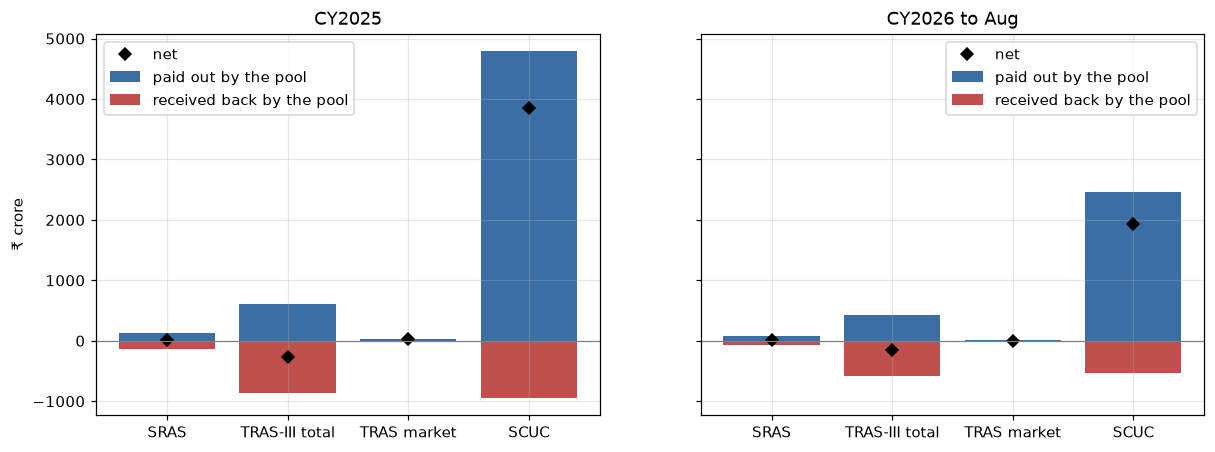

paid_out_crore  received_back_crore  net_crore  share_of_gross_paid_out
period        group                                                                                  
CY2025        SCUC                   4791.07              -941.38    3849.69                     0.86
              SRAS                    134.08              -128.37       5.71                     0.02
              TRAS market              36.06                -8.38      27.68                     0.01
              TRAS-III total          603.95              -866.49    -262.54                     0.11
CY2026 to Aug SCUC                   2458.31              -529.72    1928.59                     0.82
              SRAS                     80.07               -73.95       6.12                     0.03
              TRAS market              17.05               -13.41       3.64                     0.01
              TRAS-III total          432.24              -584.02    -151.78                     0.14

In [9]:
GROUP = {"SRAS": "SRAS", "TRAS_III_TOTAL": "TRAS-III total", "TRAS_MARKET_DAM": "TRAS market",
         "TRAS_MARKET_RTM": "TRAS market", "SCUC": "SCUC"}
money = facts_df[facts_df["mechanism"].isin(GROUP) & facts_df["measure"].isin(["energy_charges", "incentive", "commitment_charges"])]
money = money.assign(group=money["mechanism"].map(GROUP), out=money["value"].clip(lower=0), back=money["value"].clip(upper=0))
gross = money.groupby(["period", "group"])[["out", "back"]].sum().div(CRORE)
gross.columns = ["paid_out_crore", "received_back_crore"]
gross["net_crore"] = gross["paid_out_crore"] + gross["received_back_crore"]
# Check against the published net amounts (rounding of up to ₹1 per row is allowed).
pub = (facts_df[facts_df["mechanism"].isin(GROUP) & (facts_df["measure"] == "net_amount")]
       .assign(group=lambda d: d["mechanism"].map(GROUP)).groupby(["period", "group"])["value"].sum().div(CRORE))
assert (gross["net_crore"] - pub).abs().max() < 0.01, (gross["net_crore"] - pub)
gross["share_of_gross_paid_out"] = gross["paid_out_crore"] / gross.groupby(level="period")["paid_out_crore"].transform("sum")
T_Q2_GROSS = save_tab(gross.reset_index(), "09_q2_gross_flows.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (p, d) in zip(axes, gross.groupby(level="period")):
    d = d.droplevel("period").reindex(list(MECH))
    x = np.arange(len(d))
    ax.bar(x, d["paid_out_crore"], color="#3b6ea5", label="paid out by the pool")
    ax.bar(x, d["received_back_crore"], color="#c0504d", label="received back by the pool")
    ax.plot(x, d["net_crore"], "kD", label="net")
    ax.set_xticks(x, d.index); ax.axhline(0, color="grey", lw=0.8); ax.set_title(p); ax.legend()
axes[0].set_ylabel("₹ crore")
F_Q2_GROSS = save_fig(fig, "09_q2_gross_flows.png")
gross.round(2)

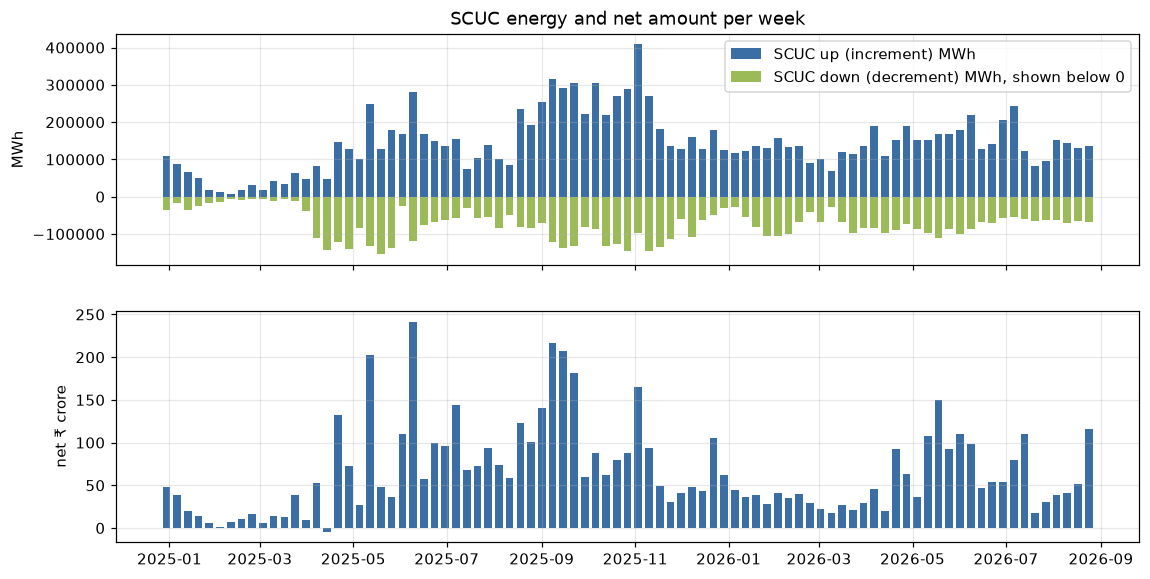

In [10]:
scuc = weekly[["week_start", "SCUC_up_mwh", "SCUC_down_mwh", "SCUC_net_crore"]]
T_Q2_SCUC = save_tab(scuc, "09_q2_scuc_weekly.csv")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
a1.bar(scuc["week_start"], scuc["SCUC_up_mwh"], width=5, color="#3b6ea5", label="SCUC up (increment) MWh")
a1.bar(scuc["week_start"], -scuc["SCUC_down_mwh"], width=5, color="#9bbb59", label="SCUC down (decrement) MWh, shown below 0")
a1.set_ylabel("MWh"); a1.legend(); a1.set_title("SCUC energy and net amount per week")
a2.bar(scuc["week_start"], scuc["SCUC_net_crore"], width=5, color="#3b6ea5")
a2.set_ylabel("net ₹ crore")
F_Q2_SCUC = save_fig(fig, "09_q2_scuc_weekly.png")

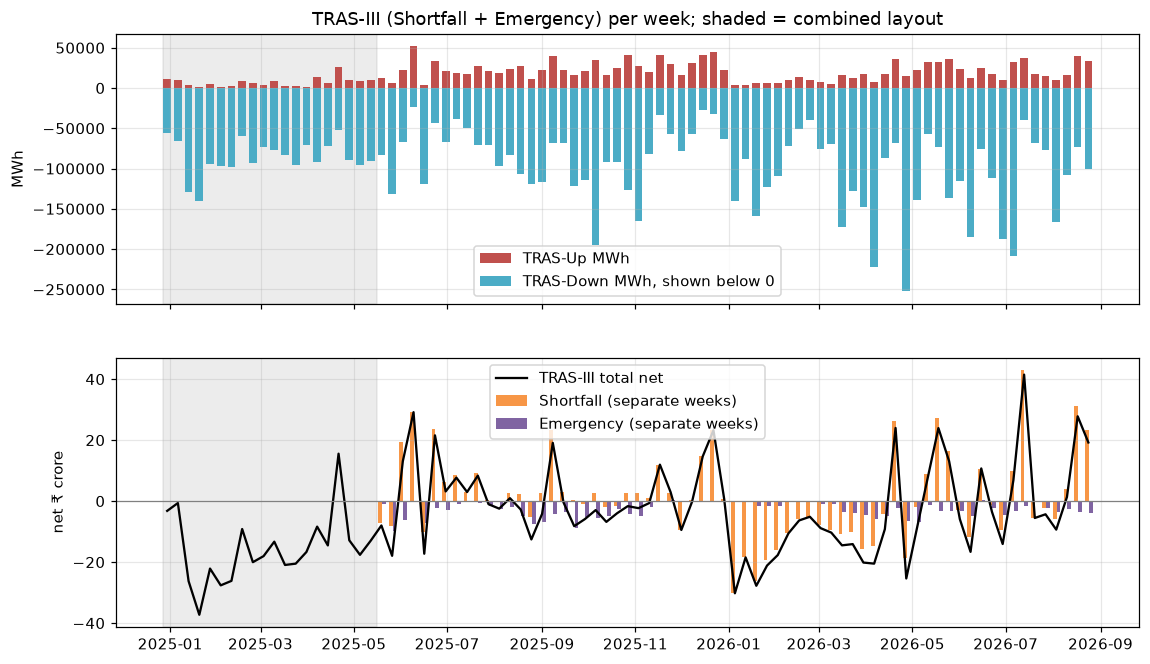

,TRAS_III_TOTAL_up_mwh,TRAS_III_TOTAL_down_mwh,TRAS_III_TOTAL_net_crore,TRAS_SHORTFALL_net_crore,TRAS_EMERGENCY_net_crore
period,,,,,
CY2025,951569.64,4423954.86,-262.538540,151.465292,-101.329496
CY2026 to Aug,629600.32,3992589.51,-151.778654,-62.272748,-89.505906


In [11]:
t3 = weekly[["week_start", "period", "TRAS_III_TOTAL_up_mwh", "TRAS_III_TOTAL_down_mwh", "TRAS_III_TOTAL_net_crore",
             "TRAS_SHORTFALL_net_crore", "TRAS_EMERGENCY_net_crore", "TRAS_SHORTFALL_available"]].copy()
# Shortfall and Emergency only exist for separate-layout weeks.
for c in ["TRAS_SHORTFALL_net_crore", "TRAS_EMERGENCY_net_crore"]:
    t3.loc[~t3["TRAS_SHORTFALL_available"], c] = np.nan
T_Q2_TRAS3 = save_tab(t3.drop(columns="TRAS_SHORTFALL_available"), "09_q2_tras3_weekly.csv")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax in (a1, a2):
    ax.axvspan(weekly["week_start"].min() - pd.Timedelta(days=3), COMBINED_END + pd.Timedelta(days=4), color="grey", alpha=0.15)
a1.bar(t3["week_start"], t3["TRAS_III_TOTAL_up_mwh"], width=5, color="#c0504d", label="TRAS-Up MWh")
a1.bar(t3["week_start"], -t3["TRAS_III_TOTAL_down_mwh"], width=5, color="#4bacc6", label="TRAS-Down MWh, shown below 0")
a1.set_ylabel("MWh"); a1.legend(); a1.set_title("TRAS-III (Shortfall + Emergency) per week; shaded = combined layout")
a2.plot(t3["week_start"], t3["TRAS_III_TOTAL_net_crore"], "k-", label="TRAS-III total net")
a2.bar(t3["week_start"] - pd.Timedelta(days=1), t3["TRAS_SHORTFALL_net_crore"], width=2.5, color="#f79646", label="Shortfall (separate weeks)")
a2.bar(t3["week_start"] + pd.Timedelta(days=1.5), t3["TRAS_EMERGENCY_net_crore"], width=2.5, color="#8064a2", label="Emergency (separate weeks)")
a2.axhline(0, color="grey", lw=0.8); a2.set_ylabel("net ₹ crore"); a2.legend()
F_Q2_TRAS3 = save_fig(fig, "09_q2_tras3_weekly.png")
t3_year = t3.groupby("period")[["TRAS_III_TOTAL_up_mwh", "TRAS_III_TOTAL_down_mwh", "TRAS_III_TOTAL_net_crore",
                                "TRAS_SHORTFALL_net_crore", "TRAS_EMERGENCY_net_crore"]].sum(min_count=1)
t3_year

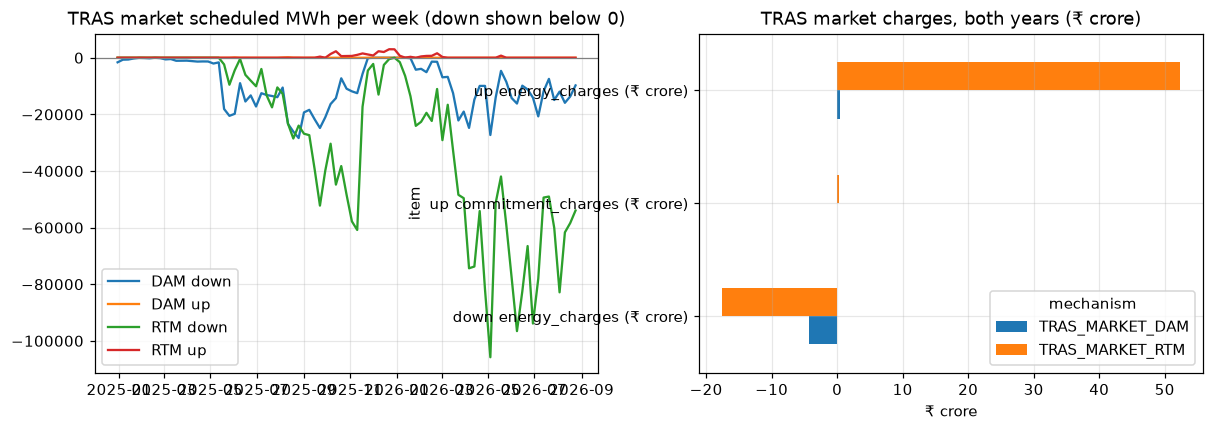

item                           down energy_charges (₹ crore)  down energy_mwh (MWh)  net net_amount (₹ crore)  up cleared_mwh (MWh)  up commitment_charges (₹ crore)  up energy_charges (₹ crore)  \
period        mechanism                                                                                                                                                                             
CY2025        TRAS_MARKET_DAM                         -2.838              454501.45                    -2.331                887.60                            0.008                        0.498   
              TRAS_MARKET_RTM                         -5.547              680777.16                    30.012              25337.89                            0.152                       35.406   
CY2026 to Aug TRAS_MARKET_DAM                         -1.400              369257.37                    -1.388                 15.00                            0.000                        0.012   
              TRAS_MARKET_RTM                        -12.014             1750445.78                     5.029              13771.71                            0.106                       16.937   

item                           up energy_mwh (MWh)  
period        mechanism                             
CY2025        TRAS_MARKET_DAM               498.40  
              TRAS_MARKET_RTM             17730.15  
CY2026 to Aug TRAS_MARKET_DAM                12.00  
              TRAS_MARKET_RTM              8479.38

In [12]:
mk = facts_df[facts_df["mechanism"].isin(["TRAS_MARKET_DAM", "TRAS_MARKET_RTM"])]
mk_sum = (mk.assign(item=mk["direction"].fillna("net").replace("", "net") + " " + mk["measure"])
            .pivot_table(index=["period", "mechanism"], columns="item", values="value", aggfunc="sum").fillna(0))
for c in [c for c in mk_sum.columns if not c.endswith("mwh")]:
    mk_sum[c] = mk_sum[c] / CRORE
mk_sum = mk_sum.rename(columns={c: (c + " (MWh)" if c.endswith("mwh") else c + " (₹ crore)") for c in mk_sum.columns})
T_Q2_MARKET = save_tab(mk_sum.reset_index(), "09_q2_market_summary.csv")
mkw = (mk[(mk["measure"] == "energy_mwh")].pivot_table(index="week_start", columns=["mechanism", "direction"],
                                                       values="value", aggfunc="sum").fillna(0))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
for (m, d), s in mkw.items():
    a1.plot(s.index, s.values if d == "up" else -s.values, label=f"{m.split('_')[-1]} {d}")
a1.axhline(0, color="grey", lw=0.8); a1.set_title("TRAS market scheduled MWh per week (down shown below 0)"); a1.legend()
charge_cols = [c for c in mk_sum.columns if "charges" in c]
mk_sum[charge_cols].groupby(level="mechanism").sum().T.plot.barh(ax=a2)
a2.set_title("TRAS market charges, both years (₹ crore)"); a2.set_xlabel("₹ crore")
F_Q2_MARKET = save_fig(fig, "09_q2_market.png")
mk_sum.round(3)

### What the data shows

In [13]:
s = share
lines = [f"{m}: CY2025 {cr(s.at[m, 'CY2025'])} ({s.at[m, 'CY2025 share of total net']:.1%} of total net); CY2026 to Aug "
         f"{cr(s.at[m, 'CY2026 to Aug'])} ({s.at[m, 'CY2026 to Aug share of total net']:.1%}) ({T_Q2_SHARE})." for m in MECH]
neg_t3 = int((weekly["TRAS_III_TOTAL_net_crore"] < 0).sum())
g = gross
for p in ("CY2025", "CY2026 to Aug"):
    lines.append(f"{p}: the pool paid out {cr(g.loc[p, 'paid_out_crore'].sum())} gross and received back "
                 f"{cr(-g.loc[p, 'received_back_crore'].sum())}; SCUC was {g.at[(p, 'SCUC'), 'share_of_gross_paid_out']:.1%} "
                 f"of gross payouts ({T_Q2_GROSS}, {F_Q2_GROSS}).")
lines.append("SCUC's share of the total net exceeds 100% because the other mechanisms together have a negative net "
             f"(the pool received more than it paid for them), so the total net is smaller than SCUC's net alone ({T_Q2_SHARE}).")
lines += [
    f"TRAS-III total net was negative (paid into the pool) in {neg_t3} of 87 weeks; totals: "
    f"CY2025 {cr(t3_year.at['CY2025', 'TRAS_III_TOTAL_net_crore'])}, CY2026 to Aug "
    f"{cr(t3_year.at['CY2026 to Aug', 'TRAS_III_TOTAL_net_crore'])} ({T_Q2_TRAS3}, {F_Q2_TRAS3}).",
    f"TRAS-III energy, both years: up {weekly['TRAS_III_TOTAL_up_mwh'].sum():,.0f} MWh, down "
    f"{weekly['TRAS_III_TOTAL_down_mwh'].sum():,.0f} MWh ({T_Q2_TRAS3}).",
    f"Separate-layout weeks only: Shortfall net {cr(t3['TRAS_SHORTFALL_net_crore'].sum())}, Emergency net "
    f"{cr(t3['TRAS_EMERGENCY_net_crore'].sum())} ({T_Q2_TRAS3}).",
    f"SCUC energy, both years: up {weekly['SCUC_up_mwh'].sum():,.0f} MWh, down {weekly['SCUC_down_mwh'].sum():,.0f} MWh; "
    f"net {cr(weekly['SCUC_net_crore'].sum())}; SCUC net was positive in {int((weekly['SCUC_net_crore'] > 0).sum())} of 87 weeks "
    f"({T_Q2_SCUC}).",
]
m2 = mk_sum.groupby(level="mechanism").sum()
for m in m2.index:
    lines.append(f"{m}, both years: up scheduled {m2.at[m, 'up energy_mwh (MWh)']:,.0f} MWh, down scheduled "
                 f"{m2.at[m, 'down energy_mwh (MWh)']:,.0f} MWh, up energy charges {cr(m2.at[m, 'up energy_charges (₹ crore)'])}, "
                 f"commitment charges {cr(m2.at[m, 'up commitment_charges (₹ crore)'])}, net {cr(m2.at[m, 'net net_amount (₹ crore)'])} "
                 f"({T_Q2_MARKET}).")
facts(lines)
for p in ("CY2025", "CY2026 to Aug"):
    key("Q2", f"SCUC share of total net, {p}", round(s.at["SCUC", f"{p} share of total net"] * 100, 1), "%", T_Q2_SHARE)
    key("Q2", f"TRAS-III total net, {p}", round(s.at["TRAS-III total", p], 2), "₹ crore", T_Q2_SHARE)
key("Q2", "Weeks with TRAS-III net paid into the pool", neg_t3, "weeks of 87", T_Q2_TRAS3)
for p in ("CY2025", "CY2026 to Aug"):
    key("Q2", f"Gross paid out by the pool, {p}", round(gross.loc[p, "paid_out_crore"].sum(), 2), "₹ crore", T_Q2_GROSS)
    key("Q2", f"Gross received back by the pool, {p}", round(-gross.loc[p, "received_back_crore"].sum(), 2), "₹ crore", T_Q2_GROSS)
    key("Q2", f"SCUC share of gross payouts, {p}", round(gross.at[(p, "SCUC"), "share_of_gross_paid_out"] * 100, 1), "%", T_Q2_GROSS)

- SRAS: CY2025 ₹5.71 crore (0.2% of total net); CY2026 to Aug ₹6.12 crore (0.3%) (outputs/tables/09_q2_mechanism_share_by_year.csv).
- TRAS-III total: CY2025 ₹-262.54 crore (-7.3% of total net); CY2026 to Aug ₹-151.78 crore (-8.5%) (outputs/tables/09_q2_mechanism_share_by_year.csv).
- TRAS market: CY2025 ₹27.68 crore (0.8% of total net); CY2026 to Aug ₹3.64 crore (0.2%) (outputs/tables/09_q2_mechanism_share_by_year.csv).
- SCUC: CY2025 ₹3,849.69 crore (106.3% of total net); CY2026 to Aug ₹1,928.59 crore (107.9%) (outputs/tables/09_q2_mechanism_share_by_year.csv).
- CY2025: the pool paid out ₹5,565.17 crore gross and received back ₹1,944.63 crore; SCUC was 86.1% of gross payouts (outputs/tables/09_q2_gross_flows.csv, outputs/figures/09_q2_gross_flows.png).
- CY2026 to Aug: the pool paid out ₹2,987.68 crore gross and received back ₹1,201.11 crore; SCUC was 82.3% of gross payouts (outputs/tables/09_q2_gross_flows.csv, outputs/figures/09_q2_gross_flows.png).
- SCUC's share of the total net exceeds 100% because the other mechanisms together have a negative net (the pool received more than it paid for them), so the total net is smaller than SCUC's net alone (outputs/tables/09_q2_mechanism_share_by_year.csv).
- TRAS-III total net was negative (paid into the pool) in 62 of 87 weeks; totals: CY2025 ₹-262.54 crore, CY2026 to Aug ₹-151.78 crore (outputs/tables/09_q2_tras3_weekly.csv, outputs/figures/09_q2_tras3_weekly.png).
- TRAS-III energy, both years: up 1,581,170 MWh, down 8,416,544 MWh (outputs/tables/09_q2_tras3_weekly.csv).
- Separate-layout weeks only: Shortfall net ₹89.19 crore, Emergency net ₹-190.84 crore (outputs/tables/09_q2_tras3_weekly.csv).
- SCUC energy, both years: up 12,667,739 MWh, down 6,495,057 MWh; net ₹5,778.28 crore; SCUC net was positive in 86 of 87 weeks (outputs/tables/09_q2_scuc_weekly.csv).
- TRAS_MARKET_DAM, both years: up scheduled 510 MWh, down scheduled 823,759 MWh, up energy charges ₹0.51 crore, commitment charges ₹0.01 crore, net ₹-3.72 crore (outputs/tables/09_q2_market_summary.csv).
- TRAS_MARKET_RTM, both years: up scheduled 26,210 MWh, down scheduled 2,431,223 MWh, up energy charges ₹52.34 crore, commitment charges ₹0.26 crore, net ₹35.04 crore (outputs/tables/09_q2_market_summary.csv).

### Questions to interpret

- Why is SCUC 86.1% (2025) and 82.3% (2026) of gross payouts, while the pool also receives back about a third
  of what it pays out overall (`09_q2_gross_flows.csv`)?
- Why do the other mechanisms together have a negative net, so that SCUC exceeds 100% of the total net
  (`09_q2_mechanism_share_by_year.csv`)?
- Why does TRAS-III receive back more than it pays out in both years, while SRAS's paid out and received back nearly
  offset each other (`09_q2_gross_flows.csv`)?
- Why is TRAS-III a net inflow to the pool in 62 of 87 weeks, with TRAS-Down energy about five times TRAS-Up
  (`09_q2_tras3_weekly.csv`)?
- In separate-layout weeks, why is Shortfall a net payment from the pool but Emergency a net payment into it?
- Why is SCUC-Up energy about twice SCUC-Down energy, and why is SCUC net positive in 86 of 87 weeks
  (`09_q2_scuc_weekly.csv`)?
- Why is the Day-Ahead TRAS market almost all TRAS-Down (510 MWh up vs 823,759 MWh down), and why is Real-Time
  market activity larger than Day-Ahead (`09_q2_market_summary.csv`)?

## Q3. Who gets paid? (by plant_id)

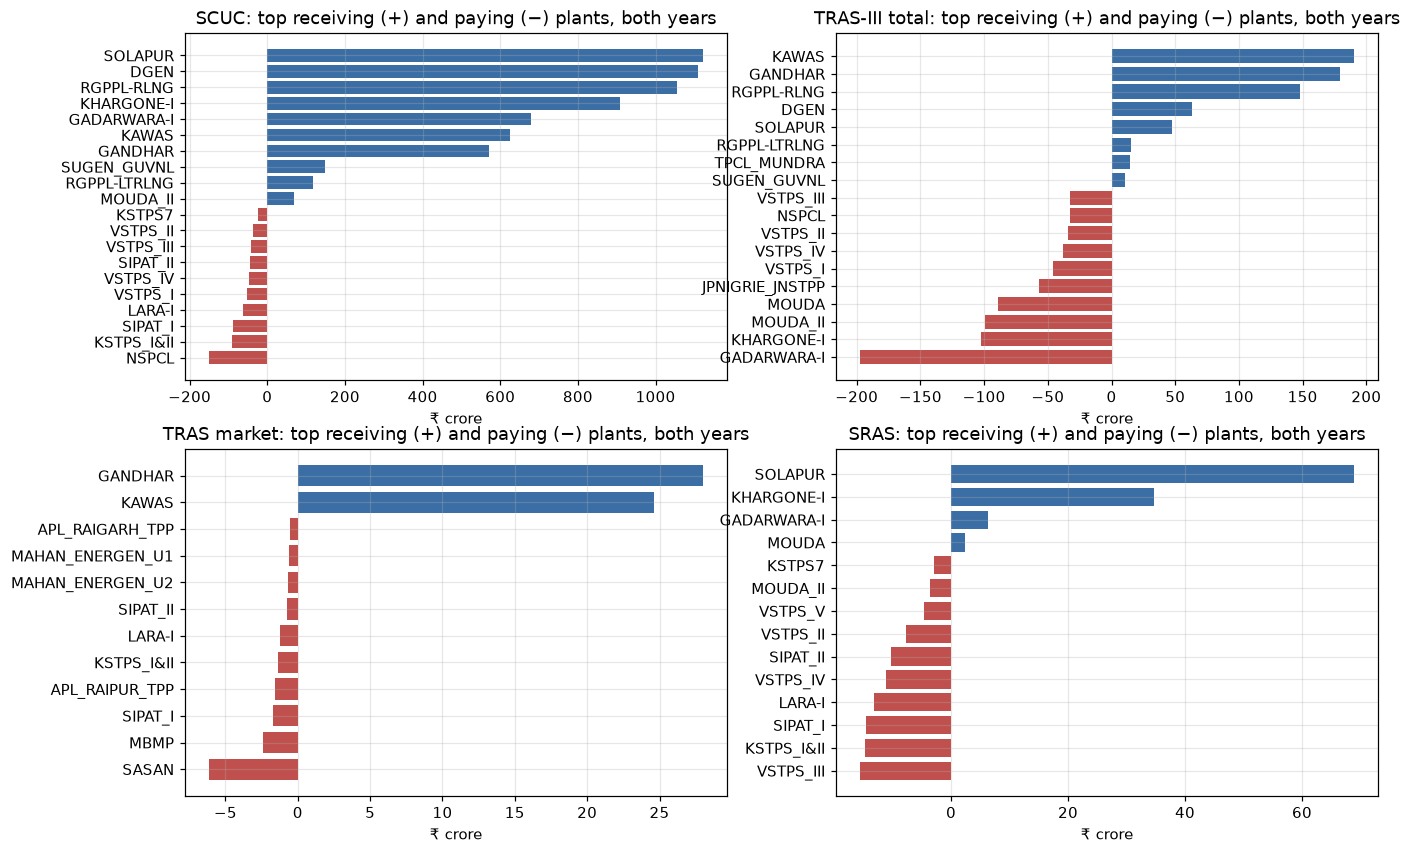

,group,plant_id,net_crore,side
16,SCUC,SOLAPUR,1120.959738,receives
0,SCUC,DGEN,1110.473778,receives
12,SCUC,RGPPL-RLNG,1055.323070,receives
4,SCUC,KHARGONE-I,907.983924,receives
1,SCUC,GADARWARA-I,678.453393,receives
10,SCUC,NSPCL,-149.154964,pays
6,SCUC,KSTPS_I&II,-92.110773,pays
14,SCUC,SIPAT_I,-88.273001,pays
7,SCUC,LARA-I,-63.707439,pays
18,SCUC,VSTPS_I,-52.669634,pays


In [14]:
MECH_GROUP = {"SRAS": "SRAS", "TRAS_III_TOTAL": "TRAS-III total", "TRAS_MARKET_DAM": "TRAS market",
              "TRAS_MARKET_RTM": "TRAS market", "SCUC": "SCUC"}
net = facts_df[(facts_df["measure"] == "net_amount") & facts_df["mechanism"].isin(MECH_GROUP)].copy()
net["group"] = net["mechanism"].map(MECH_GROUP)
plant_net = net.groupby(["group", "plant_id"])["value"].sum().div(CRORE).rename("net_crore").reset_index()
rows = []
for g, d in plant_net.groupby("group"):
    d = d.sort_values("net_crore", ascending=False)
    rows.append(d[d["net_crore"] > 0].head(10).assign(side="receives"))
    rows.append(d[d["net_crore"] < 0].tail(10).sort_values("net_crore").assign(side="pays"))
top_plants = pd.concat(rows)
T_Q3_TOP = save_tab(top_plants, "09_q3_top_plants_by_mechanism.csv")
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, g in zip(axes.flat, ["SCUC", "TRAS-III total", "TRAS market", "SRAS"]):
    d = top_plants[top_plants["group"] == g].sort_values("net_crore")
    ax.barh(d["plant_id"], d["net_crore"], color=np.where(d["net_crore"] > 0, "#3b6ea5", "#c0504d"))
    ax.set_title(f"{g}: top receiving (+) and paying (−) plants, both years"); ax.set_xlabel("₹ crore")
F_Q3_TOP = save_fig(fig, "09_q3_top_plants.png")
top_plants.groupby(["group", "side"]).head(5)

In [15]:
def concentration(series):
    rec = series[series > 0]
    shares = rec / rec.sum()
    return pd.Series({"receiving_plants": len(rec), "receipts_crore": rec.sum(),
                      "top5_share": shares.sort_values(ascending=False).head(5).sum(),
                      "hhi": float((shares * 100).pow(2).sum())})

conc = plant_net.groupby("group").apply(lambda d: concentration(d.set_index("plant_id")["net_crore"]))
conc.loc["All mechanisms"] = concentration(plant_net.groupby("plant_id")["net_crore"].sum())
T_Q3_CONC = save_tab(conc.reset_index(names="mechanism"), "09_q3_concentration.csv")
conc.round(3)

,receiving_plants,receipts_crore,top5_share,hhi
group,,,,
SCUC,11.0,6453.155,0.755,1356.000
SRAS,4.0,112.062,1.000,4764.545
TRAS market,2.0,52.585,1.000,5020.440
TRAS-III total,8.0,667.979,0.939,2169.932
All mechanisms,10.0,6863.715,0.771,1411.850


Receipts = each plant's net amount over both years where positive. HHI = Σ (share × 100)² over receiving plants (0–10,000).

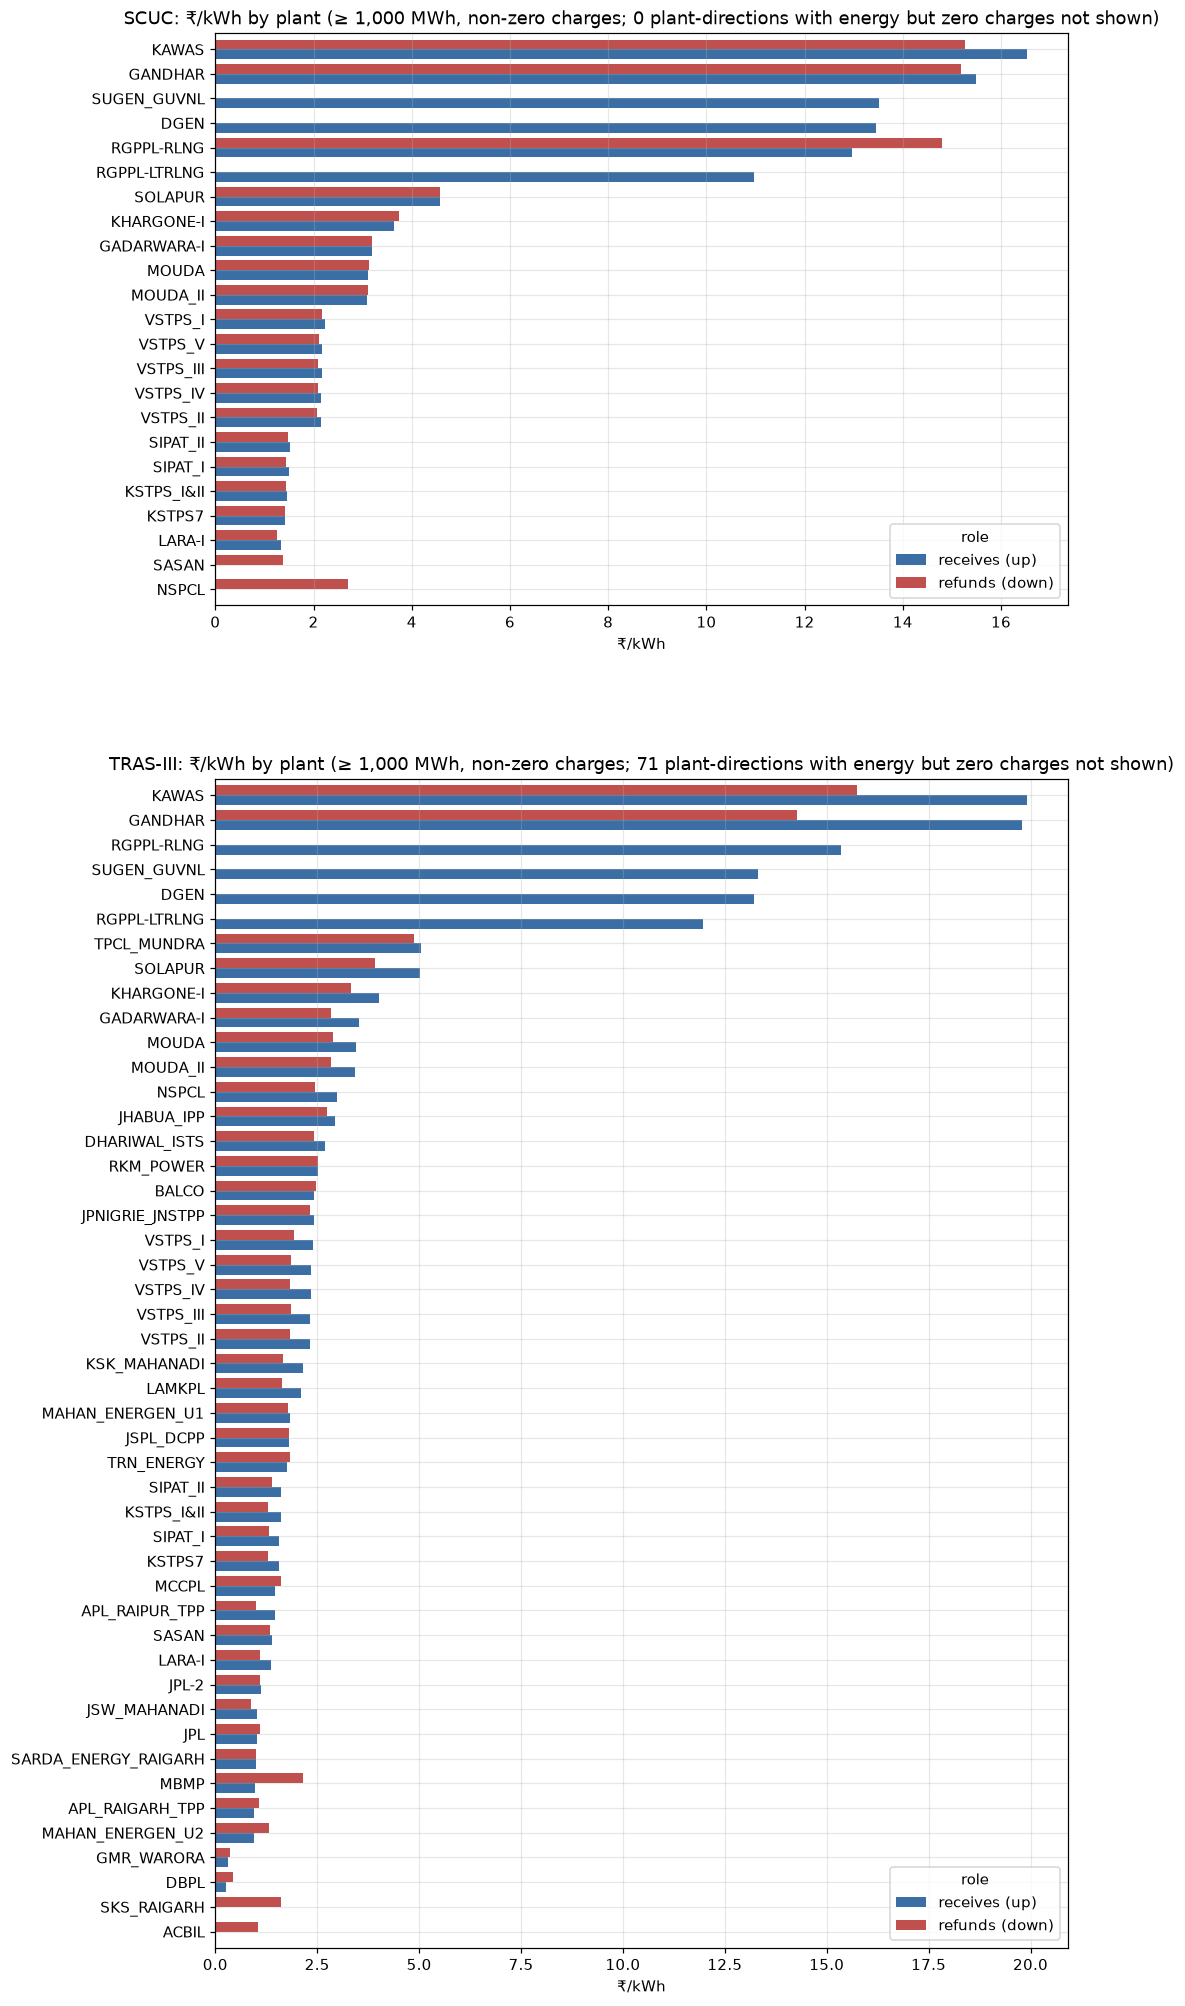

count  mean   std   min   25%   50%   75%    max
mechanism role                                                            
SCUC      receives (up)    23.0  5.34  5.29  1.35  1.84  2.82  7.77  16.53
          refunds (down)   22.0  4.91  5.03  1.25  1.62  2.43  4.36  15.26
TRAS-III  receives (up)    48.0  3.70  4.80  0.00  1.38  2.13  3.10  19.92
          refunds (down)  114.0  1.02  2.32  0.00  0.00  0.00  1.37  15.74

In [16]:
def rates(mech, label):
    f = facts_df[(facts_df["mechanism"] == mech) & facts_df["direction"].isin(["up", "down"])]
    p = f.pivot_table(index=["plant_id", "direction"], columns="measure", values="value", aggfunc="sum").reset_index()
    p["mechanism"] = label
    p["rate_rs_per_kwh"] = np.where(p["energy_mwh"] > 0, p["energy_charges"].abs() / (p["energy_mwh"] * 1000), np.nan)
    return p[["mechanism", "plant_id", "direction", "energy_mwh", "energy_charges", "rate_rs_per_kwh"]]

rate_tab = pd.concat([rates("SCUC", "SCUC"), rates("TRAS_III_TOTAL", "TRAS-III")], ignore_index=True)
rate_tab["role"] = rate_tab["direction"].map({"up": "receives (up)", "down": "refunds (down)"})
T_Q3_RATES = save_tab(rate_tab, "09_q3_rates_per_plant.csv")
MIN_MWH = 1000  # chart: plant-directions with at least this much energy and non-zero charges (the table keeps all)
shown = rate_tab[(rate_tab["energy_mwh"] >= MIN_MWH) & (rate_tab["energy_charges"] != 0)]
zero_charge = rate_tab[(rate_tab["energy_mwh"] > 0) & (rate_tab["energy_charges"] == 0)]
n_plants = {m: shown.loc[shown["mechanism"] == m, "plant_id"].nunique() for m in ["SCUC", "TRAS-III"]}
fig, axes = plt.subplots(2, 1, figsize=(10, 0.28 * sum(n_plants.values()) + 3),
                         gridspec_kw={"height_ratios": [n_plants["SCUC"], n_plants["TRAS-III"]]})
for ax, m in zip(axes, ["SCUC", "TRAS-III"]):
    w = (shown[shown["mechanism"] == m].pivot(index="plant_id", columns="role", values="rate_rs_per_kwh")
         .reindex(columns=["receives (up)", "refunds (down)"]).sort_values("receives (up)", na_position="first"))
    w.plot.barh(ax=ax, color=["#3b6ea5", "#c0504d"], width=0.8)
    nz = zero_charge[zero_charge["mechanism"] == m]
    ax.set_title(f"{m}: ₹/kWh by plant (≥ {MIN_MWH:,} MWh, non-zero charges; "
                 f"{len(nz)} plant-directions with energy but zero charges not shown)")
    ax.set_xlabel("₹/kWh"); ax.set_ylabel("")
F_Q3_RATES = save_fig(fig, "09_q3_rates.png")
rate_tab.groupby(["mechanism", "role"])["rate_rs_per_kwh"].describe().round(2)

Rates: charges ÷ energy in the same direction. SCUC up = charges paid to the generator ÷ increment energy;
SCUC down = charges refunded by the generator ÷ decrement energy; TRAS-III up/down likewise (charges ÷ TRAS-Up/Down energy).

In [17]:
GAS_TOKENS = {"RLNG", "APM", "NAPM", "COMGAS", "LTRLNG", "ZLIQ"}
stations = facts_df[["station_id"]].drop_duplicates()
stations["stream"] = np.where(stations["station_id"].map(lambda s: bool(set(re.split(r"[-_\s]+", s.upper())) & GAS_TOKENS)),
                              "gas fuel stream (by name)", "other")
stream_of = dict(zip(stations["station_id"], stations["stream"]))
sc = facts_df[facts_df["mechanism"] == "SCUC"].assign(stream=lambda d: d["station_id"].map(stream_of))
st_net = sc[sc["measure"] == "net_amount"].groupby(["stream", "station_id"])["value"].sum()
receipts = st_net[st_net > 0].groupby(level="stream").sum() / CRORE
up = sc[sc["direction"] == "up"].pivot_table(index="stream", columns="measure", values="value", aggfunc="sum")
gas = pd.DataFrame({"stations": stations["stream"].value_counts(),
                    "scuc_receipts_crore": receipts,
                    "share_of_scuc_receipts": receipts / receipts.sum(),
                    "scuc_up_rate_rs_per_kwh (energy-weighted)": up["energy_charges"] / (up["energy_mwh"] * 1000)})
gas_names = sorted(s for s, v in stream_of.items() if v != "other")
T_Q3_GAS = save_tab(gas.reset_index(names="stream"), "09_q3_gas_fuel_streams.csv")
print("gas fuel stream stations (by name):", ", ".join(gas_names))
gas.round(3)

gas fuel stream stations (by name): GANDHAR-APM, GANDHAR-COMGAS, GANDHAR-NAPM, GANDHAR-RLNG, KAWAS-APM, KAWAS-COMGAS, KAWAS-NAPM, KAWAS-RLNG, KAWAS-ZLIQ, RGPPL-LTRLNG, RGPPL-RLNG


,stations,scuc_receipts_crore,share_of_scuc_receipts,scuc_up_rate_rs_per_kwh (energy-weighted)
stream,,,,
gas fuel stream (by name),11,2367.366,0.367,14.220
other,118,4085.789,0.633,4.408


### What the data shows

In [18]:
lines = []
for g in ["SCUC", "TRAS-III total", "TRAS market", "SRAS"]:
    d = top_plants[top_plants["group"] == g]
    r, p = d[d["side"] == "receives"].head(1), d[d["side"] == "pays"].head(1)
    lines.append(f"{g}: largest receiver {r['plant_id'].iloc[0] if len(r) else '-'} "
                 f"({cr(r['net_crore'].iloc[0]) if len(r) else '-'}); largest payer "
                 f"{p['plant_id'].iloc[0] if len(p) else '-'} ({cr(p['net_crore'].iloc[0]) if len(p) else '-'}) ({T_Q3_TOP}).")
for g in conc.index:
    lines.append(f"Receipts concentration, {g}: {int(conc.at[g, 'receiving_plants'])} receiving plants, top-5 share "
                 f"{conc.at[g, 'top5_share']:.1%}, HHI {conc.at[g, 'hhi']:,.0f} ({T_Q3_CONC}).")
rs = rate_tab.groupby(["mechanism", "role"])["rate_rs_per_kwh"].median()
lines += [f"Median plant rate, {m} {role}: ₹{v:.2f}/kWh ({T_Q3_RATES})." for (m, role), v in rs.items()]
lines.append(f"Gas fuel streams (by name, {len(gas_names)} stations): {gas.at['gas fuel stream (by name)', 'share_of_scuc_receipts']:.1%} "
             f"of SCUC receipts; SCUC-Up rate ₹{gas.at['gas fuel stream (by name)', 'scuc_up_rate_rs_per_kwh (energy-weighted)']:.2f}/kWh "
             f"vs ₹{gas.at['other', 'scuc_up_rate_rs_per_kwh (energy-weighted)']:.2f}/kWh for other ({T_Q3_GAS}).")
facts(lines)
key("Q3", "SCUC receipts: top-5 plant share", round(conc.at["SCUC", "top5_share"] * 100, 1), "%", T_Q3_CONC)
key("Q3", "SCUC receipts: HHI", round(conc.at["SCUC", "hhi"]), "index", T_Q3_CONC)
key("Q3", "All mechanisms receipts: top-5 plant share", round(conc.at["All mechanisms", "top5_share"] * 100, 1), "%", T_Q3_CONC)
key("Q3", "Gas fuel streams' share of SCUC receipts", round(gas.at["gas fuel stream (by name)", "share_of_scuc_receipts"] * 100, 1), "%", T_Q3_GAS)
key("Q3", "SCUC-Up rate, gas fuel streams / other",
    f"{gas.at['gas fuel stream (by name)', 'scuc_up_rate_rs_per_kwh (energy-weighted)']:.2f} / {gas.at['other', 'scuc_up_rate_rs_per_kwh (energy-weighted)']:.2f}",
    "₹/kWh", T_Q3_GAS)

- SCUC: largest receiver SOLAPUR (₹1,120.96 crore); largest payer NSPCL (₹-149.15 crore) (outputs/tables/09_q3_top_plants_by_mechanism.csv).
- TRAS-III total: largest receiver KAWAS (₹189.94 crore); largest payer GADARWARA-I (₹-197.14 crore) (outputs/tables/09_q3_top_plants_by_mechanism.csv).
- TRAS market: largest receiver GANDHAR (₹27.97 crore); largest payer SASAN (₹-6.11 crore) (outputs/tables/09_q3_top_plants_by_mechanism.csv).
- SRAS: largest receiver SOLAPUR (₹68.81 crore); largest payer VSTPS_III (₹-15.51 crore) (outputs/tables/09_q3_top_plants_by_mechanism.csv).
- Receipts concentration, SCUC: 11 receiving plants, top-5 share 75.5%, HHI 1,356 (outputs/tables/09_q3_concentration.csv).
- Receipts concentration, SRAS: 4 receiving plants, top-5 share 100.0%, HHI 4,765 (outputs/tables/09_q3_concentration.csv).
- Receipts concentration, TRAS market: 2 receiving plants, top-5 share 100.0%, HHI 5,020 (outputs/tables/09_q3_concentration.csv).
- Receipts concentration, TRAS-III total: 8 receiving plants, top-5 share 93.9%, HHI 2,170 (outputs/tables/09_q3_concentration.csv).
- Receipts concentration, All mechanisms: 10 receiving plants, top-5 share 77.1%, HHI 1,412 (outputs/tables/09_q3_concentration.csv).
- Median plant rate, SCUC receives (up): ₹2.82/kWh (outputs/tables/09_q3_rates_per_plant.csv).
- Median plant rate, SCUC refunds (down): ₹2.43/kWh (outputs/tables/09_q3_rates_per_plant.csv).
- Median plant rate, TRAS-III receives (up): ₹2.13/kWh (outputs/tables/09_q3_rates_per_plant.csv).
- Median plant rate, TRAS-III refunds (down): ₹0.00/kWh (outputs/tables/09_q3_rates_per_plant.csv).
- Gas fuel streams (by name, 11 stations): 36.7% of SCUC receipts; SCUC-Up rate ₹14.22/kWh vs ₹4.41/kWh for other (outputs/tables/09_q3_gas_fuel_streams.csv).

### Questions to interpret

- Why does one plant (SOLAPUR) receive the largest share of SCUC and SRAS payments
  (`09_q3_top_plants_by_mechanism.csv`)?
- Why are the largest TRAS-III payers (e.g. GADARWARA-I) and receivers (e.g. KAWAS) the plants they are?
- What explains the spread of SCUC ₹/kWh rates between plants, and the difference between receive (up) and refund
  (down) rates (`09_q3_rates.png`)?
- Why do 73 of 117 plant-level TRAS-III down entries have energy but zero charges (₹0/kWh refund rate,
  `09_q3_rates_per_plant.csv`)?
- Why is the SCUC-Up rate of stations named as gas fuel streams about three times that of other stations, and what
  does their 36.7% share of SCUC receipts reflect (`09_q3_gas_fuel_streams.csv`)?

## Q4. How reliable are the statements?

Uses the step 02 manifest, the step 05 selection and file roles, and the step 07 revision summary.

,weeks
revised complete version only,22
active overlay only,11
both,0
distinct weeks (either),33


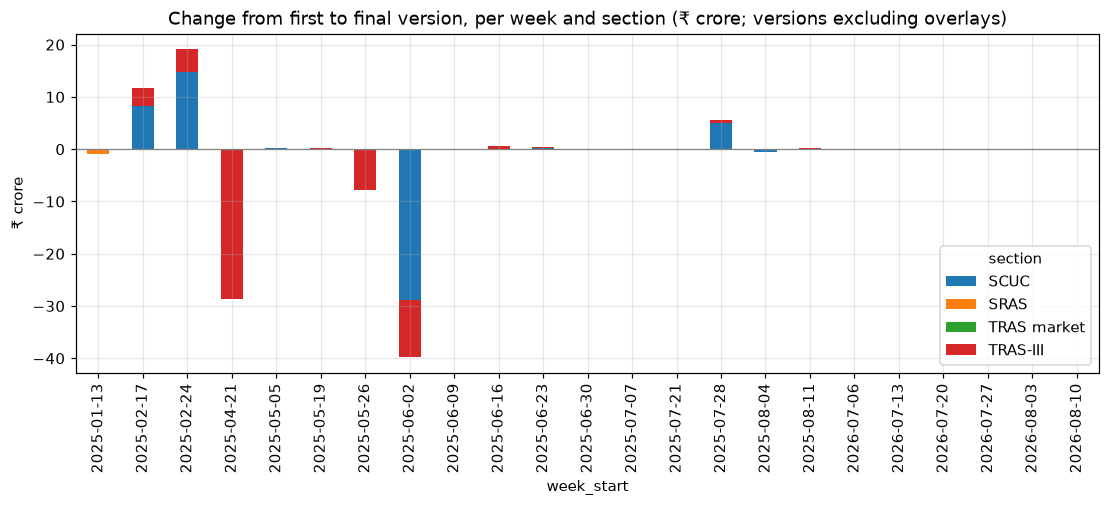

,week_start,section,versions,first_total,final_total,change_crore
61,2025-06-02,Consolidated (all),4,1.621452e+09,1.223597e+09,-39.79
44,2025-06-02,SCUC,4,1.394664e+09,1.105409e+09,-28.93
57,2025-04-21,Consolidated (all),2,1.749201e+09,1.462102e+09,-28.71
79,2025-04-21,TRAS-III,2,4.424613e+08,1.555075e+08,-28.70
56,2025-02-24,Consolidated (all),2,-2.429154e+08,-5.166406e+07,19.13
39,2025-02-24,SCUC,2,2.017605e+07,1.681228e+08,14.79
55,2025-02-17,Consolidated (all),2,-1.192440e+08,-2.249701e+06,11.70
83,2025-06-02,TRAS-III,4,2.395218e+08,1.309213e+08,-10.86
38,2025-02-17,SCUC,2,2.241274e+07,1.057565e+08,8.33
82,2025-05-26,TRAS-III,3,-1.016038e+08,-1.793090e+08,-7.77


In [19]:
manifest = pd.read_csv(config.MANIFEST_CSV, keep_default_na=False)
selection = pd.read_csv(config.SELECTION_CSV, keep_default_na=False)
roles05 = pd.read_csv(config.FILE_ROLES_CSV, keep_default_na=False)
rev = pd.read_csv(config.REVISION_SUMMARY_CSV)
SECTION_NAME = {"TRAS_III_TOTAL": "TRAS-III", "TRAS_MARKET": "TRAS market", "SRAS_PAYMENT": "SRAS",
                "SCUC": "SCUC", "CONSOLIDATED": "Consolidated (all)", "SRAS_PERFORMANCE": "SRAS performance"}
revised_weeks = set(rev.loc[~rev["identical"], "week_start"])
overlay_weeks = set(selection.loc[selection["overlays_active"] != "", "week_start"])
any_rev = revised_weeks | overlay_weeks
rev_overlap = pd.DataFrame({"weeks": [len(revised_weeks - overlay_weeks), len(overlay_weeks - revised_weeks),
                                      len(revised_weeks & overlay_weeks), len(any_rev)]},
                           index=["revised complete version only", "active overlay only", "both", "distinct weeks (either)"])
T_Q4_OVERLAP = save_tab(rev_overlap.reset_index(names="kind"), "09_q4_revision_week_overlap.csv")
display(rev_overlap)
first_final = (rev[rev["table_type"] != "SRAS_PERFORMANCE"].groupby(["week_start", "table_type"], sort=False)
               .agg(versions=("to_file", lambda s: len(s) + 1), first_total=("net_total_old", "first"),
                    final_total=("net_total_new", "last")).reset_index())
first_final["change_crore"] = (first_final["final_total"] - first_final["first_total"]) / CRORE
first_final["section"] = first_final["table_type"].map(SECTION_NAME)
T_Q4_REV = save_tab(first_final, "09_q4_revision_first_vs_final.csv")
largest = first_final.reindex(first_final["change_crore"].abs().sort_values(ascending=False).index).head(10)
fig, ax = plt.subplots(figsize=(12, 4))
pv = first_final[first_final["table_type"] != "CONSOLIDATED"].pivot_table(index="week_start", columns="section",
                                                                         values="change_crore", aggfunc="sum").fillna(0)
pv.plot.bar(ax=ax, stacked=True)
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Change from first to final version, per week and section (₹ crore; versions excluding overlays)")
ax.set_ylabel("₹ crore")
F_Q4_REV = save_fig(fig, "09_q4_revisions.png")
largest[["week_start", "section", "versions", "first_total", "final_total", "change_crore"]].round(2)

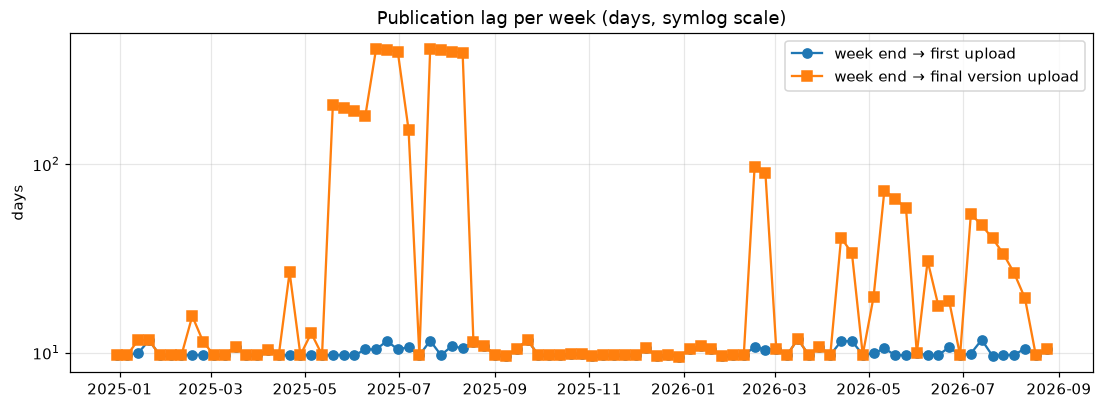

period                       CY2025  CY2026 to Aug
days_to_first_upload  count    52.0           35.0
                      mean     10.1           10.2
                      std       0.6            0.7
                      min       9.6            9.5
                      25%       9.7            9.7
                      50%       9.7            9.9
                      75%      10.4           10.5
                      max      11.7           11.8
days_to_final_version count    52.0           35.0
                      mean     80.2           27.1
                      std     138.3           24.5
                      min       9.6            9.5
                      25%       9.7            9.7
                      50%       9.8           11.8
                      75%      18.4           37.1
                      max     410.8           96.7

In [20]:
mw = manifest[(manifest["doc_type"] == "weekly_statement") & (manifest["in_window"].astype(str) == "True")].copy()
mw["upload_ts"] = pd.to_datetime(mw["upload_ts"])
first_up = mw.groupby("week_start")["upload_ts"].min()
up_of = manifest.drop_duplicates("filename").set_index("filename")["upload_ts"].pipe(pd.to_datetime)
final_files = selection.assign(files=selection["base"] + ";" + selection["overlays_active"])
final_up = (final_files.assign(f=final_files["files"].str.split(";")).explode("f").query("f != ''")
            .assign(ts=lambda d: d["f"].map(up_of)).groupby("week_start")["ts"].max())
lag = pd.DataFrame({"first_upload": first_up, "final_version_upload": final_up}).reset_index(names="week_start")
lag["week_end"] = pd.to_datetime(lag["week_start"]) + pd.Timedelta(days=6)
lag["days_to_first_upload"] = (lag["first_upload"] - lag["week_end"]).dt.total_seconds() / 86400
lag["days_to_final_version"] = (lag["final_version_upload"] - lag["week_end"]).dt.total_seconds() / 86400
lag["period"] = pd.to_datetime(lag["week_start"]).dt.isocalendar().year.map(PERIOD)
T_Q4_LAG = save_tab(lag, "09_q4_publication_lag.csv")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pd.to_datetime(lag["week_start"]), lag["days_to_first_upload"], "o-", label="week end → first upload")
ax.plot(pd.to_datetime(lag["week_start"]), lag["days_to_final_version"], "s-", label="week end → final version upload")
ax.set_ylabel("days"); ax.set_yscale("symlog"); ax.legend()
ax.set_title("Publication lag per week (days, symlog scale)")
F_Q4_LAG = save_fig(fig, "09_q4_publication_lag.png")
lag_stats = lag.groupby("period")[["days_to_first_upload", "days_to_final_version"]].describe().T
lag_stats.round(1)

In [21]:
# Files whose title described them as narrow (overlay) but whose content was a complete restatement (step 05).
mis = roles05[(roles05["step02_file_role"] == "overlay")
              & roles05[["decision_TRAS", "decision_SRAS", "decision_SCUC"]].eq("complete").any(axis=1)]
mis_files = mis.drop_duplicates("filename")[["filename", "title_scope", "week_start", "final_roles"]]
T_Q4_MIS = save_tab(mis_files, "09_q4_titles_misdescribed.csv")
narrow = roles05[(roles05["step02_file_role"] == "overlay")]["filename"].nunique()

# Data quirks recorded in docs/validation_notes.md (Open issues).
notes = config.VALIDATION_NOTES_MD.read_text(encoding="utf-8")
open_issues = notes.split("## Open issues", 1)[1]
quirks = pd.DataFrame([{"quirk": m.group(1).strip(), "detail": re.sub(r"\s+", " ", m.group(2)).strip()}
                       for m in re.finditer(r"^- \*\*(.+?)\*\*:?\s*(.+?)(?=^- \*\*|\Z)", open_issues, re.M | re.S)])
T_Q4_QUIRKS = save_tab(quirks, "09_q4_data_quirks.csv")
display(mis_files)
quirks

,filename,title_scope,week_start,final_roles
30,0608202612255208753 trasjun25.5b.pdf,TRAS_EMERGENCY_IPP,2025-06-30,TRAS:base;SRAS:base;SCUC:base
37,0608202619453824352 trasjun25.4b.pdf,TRAS_EMERGENCY_IPP,2025-06-23,TRAS:base;SRAS:base;SCUC:base
40,0608202619451321001 trasjun25.3b.pdf,TRAS_EMERGENCY_IPP,2025-06-16,TRAS:base;SRAS:base;SCUC:base
81,040920261112180532trasaug26.2a.pdf,STATION_SPECIFIC,2026-08-10,TRAS:base
82,040920261112027768trasaug26.1a.pdf,STATION_SPECIFIC,2026-08-03,TRAS:base
83,040920261111428451trasjul26.4a.pdf,STATION_SPECIFIC,2026-07-27,TRAS:base
84,040920261111255137trasjul26.3a.pdf,STATION_SPECIFIC,2026-07-20,TRAS:base
85,040920261111046976trasjul26.2b.pdf,STATION_SPECIFIC,2026-07-13,TRAS:base
86,040920261110492760trasjul26.1a.pdf,STATION_SPECIFIC,2026-07-06,TRAS:base
92,060820261224530301trasjul26.2a.pdf,STATION_SPECIFIC,2026-07-13,TRAS:superseded;SRAS:base;SCUC:base


,quirk,detail
0,SRAS performance above 100%,"167 published values above 100% (max 168.7%), ..."
1,Negative TRAS-Down MWh in the combined layout,12 selected rows (gas stations Gandhar/Kawas R...
2,Label conflict (A18),"two June 2026 overlay tables headed ""Shortfall..."
3,2025-06-30 TRAS,the IPP re-issue (trasjun25.5b) is the base; i...


### What the data shows

In [22]:
ls = lag_stats
facts([
    f"Weeks with at least one revision (distinct weeks): {len(any_rev)} of 87. {len(revised_weeks)} weeks have a revised "
    f"complete version and {len(overlay_weeks)} an active overlay; {len(revised_weeks & overlay_weeks)} weeks have both "
    f"({T_Q4_OVERLAP}).",
    f"Largest first-to-final change: {largest.iloc[0]['week_start']} {largest.iloc[0]['section']}, "
    f"{cr(largest.iloc[0]['change_crore'])} ({T_Q4_REV}, {F_Q4_REV}).",
    f"Median days from week end to first upload: CY2025 {ls.at[('days_to_first_upload', '50%'), 'CY2025']:.1f}, "
    f"CY2026 to Aug {ls.at[('days_to_first_upload', '50%'), 'CY2026 to Aug']:.1f} ({T_Q4_LAG}).",
    f"Median days from week end to the final version's upload: CY2025 {ls.at[('days_to_final_version', '50%'), 'CY2025']:.1f}, "
    f"CY2026 to Aug {ls.at[('days_to_final_version', '50%'), 'CY2026 to Aug']:.1f}; maximum "
    f"{lag['days_to_final_version'].max():.0f} days ({T_Q4_LAG}, {F_Q4_LAG}).",
    f"Files whose title described a narrow revision but whose content was a complete restatement: {len(mis_files)} of "
    f"{narrow} files titled as overlays ({T_Q4_MIS}).",
    f"Data quirks recorded in validation notes: {len(quirks)} ({T_Q4_QUIRKS}).",
])
key("Q4", "Weeks with at least one revision", len(any_rev), "weeks of 87", T_Q4_REV)
key("Q4", "Median days, week end to first upload (all weeks)", round(lag["days_to_first_upload"].median(), 1), "days", T_Q4_LAG)
key("Q4", "Median days, week end to final version (all weeks)", round(lag["days_to_final_version"].median(), 1), "days", T_Q4_LAG)
key("Q4", "Files with misdescribing titles", len(mis_files), "files", T_Q4_MIS)
key("Q4", f"Largest first-to-final revision ({largest.iloc[0]['week_start']}, {largest.iloc[0]['section']})",
    round(largest.iloc[0]["change_crore"], 2), "₹ crore", T_Q4_REV)

- Weeks with at least one revision (distinct weeks): 33 of 87. 22 weeks have a revised complete version and 11 an active overlay; 0 weeks have both (outputs/tables/09_q4_revision_week_overlap.csv).
- Largest first-to-final change: 2025-06-02 Consolidated (all), ₹-39.79 crore (outputs/tables/09_q4_revision_first_vs_final.csv, outputs/figures/09_q4_revisions.png).
- Median days from week end to first upload: CY2025 9.7, CY2026 to Aug 9.9 (outputs/tables/09_q4_publication_lag.csv).
- Median days from week end to the final version's upload: CY2025 9.8, CY2026 to Aug 11.8; maximum 411 days (outputs/tables/09_q4_publication_lag.csv, outputs/figures/09_q4_publication_lag.png).
- Files whose title described a narrow revision but whose content was a complete restatement: 10 of 19 files titled as overlays (outputs/tables/09_q4_titles_misdescribed.csv).
- Data quirks recorded in validation notes: 4 (outputs/tables/09_q4_data_quirks.csv).

### Questions to interpret

- Why were 33 of 87 weeks revised, and why are most revisions concentrated in February–August 2025
  (`09_q4_revision_first_vs_final.csv`)?
- Why were some June–August 2025 weeks re-issued more than a year later (up to 411 days after the week ended,
  `09_q4_publication_lag.csv`)?
- Why did 10 of 19 files titled as narrow (station-specific or IPP) revisions contain complete restatements
  (`09_q4_titles_misdescribed.csv`)?
- What do the recorded data quirks (`09_q4_data_quirks.csv`) imply for how far the published figures can be relied on?

## Q5. How did SRAS perform?

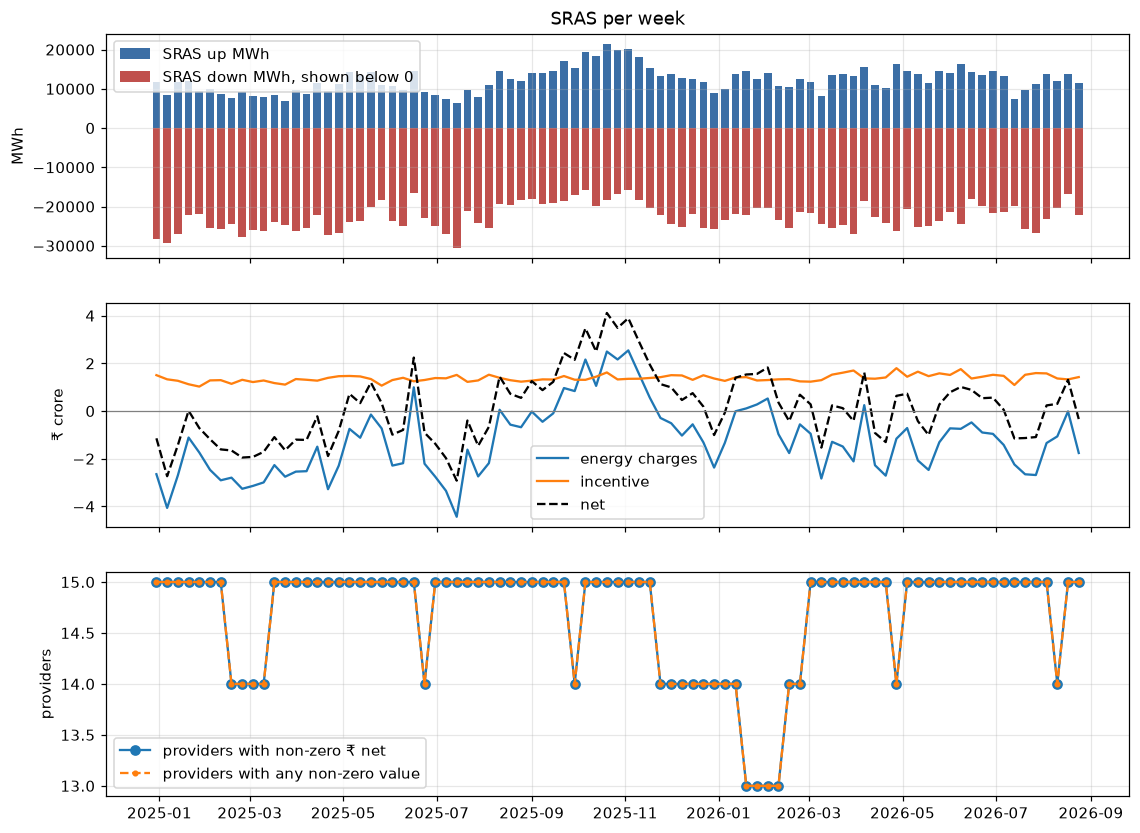

In [23]:
sr = facts_df[facts_df["mechanism"] == "SRAS"]
sras_w = (sr[sr["measure"].isin(["energy_charges", "incentive", "net_amount"])]
          .pivot_table(index="week_start", columns="measure", values="value", aggfunc="sum").div(CRORE))
sras_w = weekly.set_index("week_start")[["SRAS_up_mwh", "SRAS_down_mwh", "SRAS_providers_any", "SRAS_providers_paid"]].join(sras_w)
T_Q5_WEEKLY = save_tab(sras_w.reset_index(), "09_q5_sras_weekly.csv")
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
a1.bar(sras_w.index, sras_w["SRAS_up_mwh"], width=5, color="#3b6ea5", label="SRAS up MWh")
a1.bar(sras_w.index, -sras_w["SRAS_down_mwh"], width=5, color="#c0504d", label="SRAS down MWh, shown below 0")
a1.legend(); a1.set_ylabel("MWh"); a1.set_title("SRAS per week")
a2.plot(sras_w.index, sras_w["energy_charges"], label="energy charges")
a2.plot(sras_w.index, sras_w["incentive"], label="incentive")
a2.plot(sras_w.index, sras_w["net_amount"], "k--", label="net")
a2.axhline(0, color="grey", lw=0.8); a2.set_ylabel("₹ crore"); a2.legend()
a3.plot(sras_w.index, sras_w["SRAS_providers_paid"], "o-", label="providers with non-zero ₹ net")
a3.plot(sras_w.index, sras_w["SRAS_providers_any"], ".--", label="providers with any non-zero value")
a3.set_ylabel("providers"); a3.legend()
F_Q5_WEEKLY = save_fig(fig, "09_q5_sras_weekly.png")

/var/folders/j9/9p21ns8d687dr8fy_qzgt8mc0000gn/T/ipykernel_74481/1508596737.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([perf.loc[perf["plant_id"] == p, "performance_pct"].dropna() for p in order], tick_labels=order, vert=True)


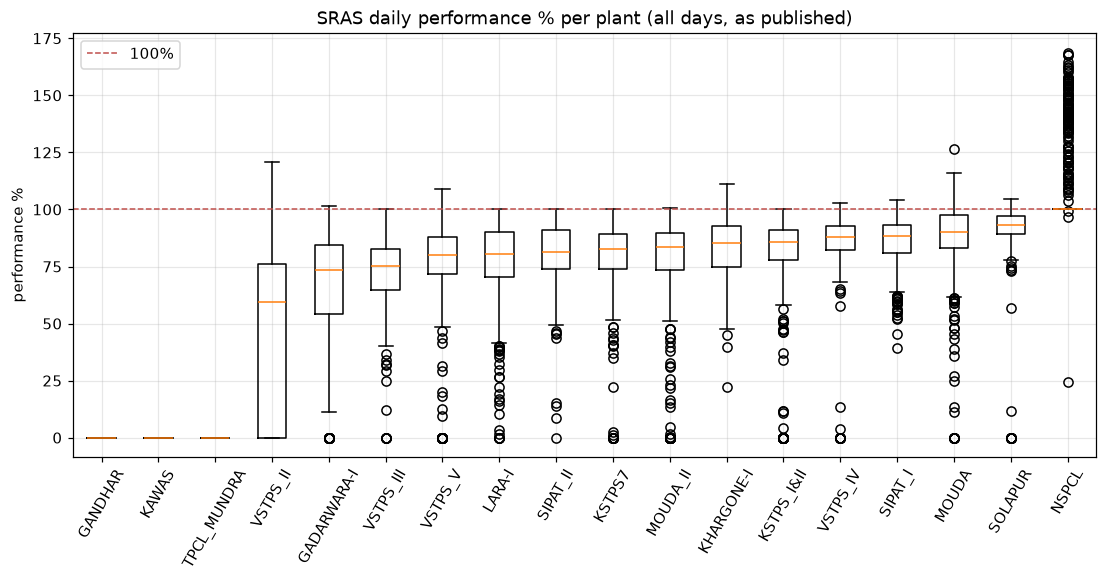

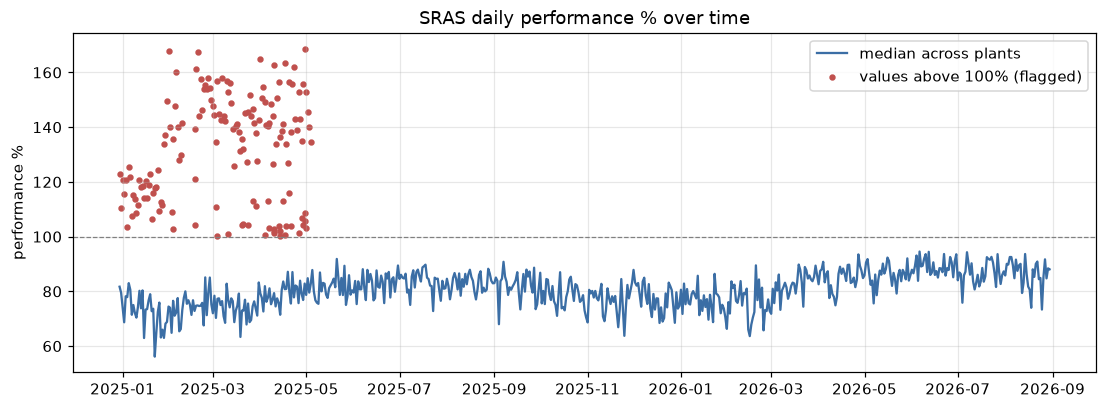

,count,mean,std,min,25%,50%,75%,max,days_above_100,days_at_0
plant_id,,,,,,,,,,
GADARWARA-I,609.0,67.4,23.4,0.0,54.3,73.6,84.4,101.5,3,32
GANDHAR,609.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,609
KAWAS,609.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,609
KHARGONE-I,609.0,83.5,11.9,22.1,74.6,85.5,92.9,111.3,1,0
KSTPS7,609.0,79.3,18.7,0.0,74.1,82.7,89.4,100.0,0,18
KSTPS_I&II,609.0,77.6,26.1,0.0,77.7,85.7,91.0,100.0,0,51
LARA-I,609.0,77.8,17.6,0.0,70.4,80.6,90.2,100.0,0,5
MOUDA,609.0,87.1,16.9,0.0,83.1,90.1,97.5,126.4,16,11
MOUDA_II,609.0,75.2,25.7,0.0,73.5,83.4,89.7,100.6,2,47


In [24]:
order = perf.groupby("plant_id")["performance_pct"].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot([perf.loc[perf["plant_id"] == p, "performance_pct"].dropna() for p in order], tick_labels=order, vert=True)
ax.axhline(100, color="#c0504d", ls="--", lw=1, label="100%")
ax.set_ylabel("performance %"); ax.tick_params(axis="x", rotation=60); ax.legend()
ax.set_title("SRAS daily performance % per plant (all days, as published)")
F_Q5_BOX = save_fig(fig, "09_q5_performance_by_plant.png")

fig, ax = plt.subplots(figsize=(12, 4))
daily_med = perf.groupby("date")["performance_pct"].median()
ax.plot(daily_med.index, daily_med.values, color="#3b6ea5", label="median across plants")
over = perf[perf["above_100"]]
ax.scatter(over["date"], over["performance_pct"], color="#c0504d", s=10, label="values above 100% (flagged)")
ax.axhline(100, color="grey", ls="--", lw=0.8); ax.set_ylabel("performance %"); ax.legend()
ax.set_title("SRAS daily performance % over time")
F_Q5_TIME = save_fig(fig, "09_q5_performance_over_time.png")
perf_tab = perf.groupby("plant_id")["performance_pct"].describe()
perf_tab["days_above_100"] = perf.groupby("plant_id")["above_100"].sum()
perf_tab["days_at_0"] = perf.groupby("plant_id")["performance_pct"].apply(lambda s: int((s == 0).sum()))
T_Q5_PLANT = save_tab(perf_tab.reset_index(), "09_q5_performance_by_plant.csv")
perf_tab.round(1)

In [25]:
BANDS = [(95, np.inf, "95%+"), (75, 95, "75–95%"), (60, 75, "60–75%"), (50, 60, "50–60%"), (20, 50, "20–50%"), (-np.inf, 20, "below 20%")]
def band(x):
    return next(lbl for lo, hi, lbl in BANDS if lo <= x < hi)
# Participating: the plant (plant_id) has non-zero SRAS up or down energy in that week.
sras_e = facts_df[(facts_df["mechanism"] == "SRAS") & (facts_df["measure"] == "energy_mwh")
                  & facts_df["direction"].isin(["up", "down"])]
active = sras_e[sras_e["value"].fillna(0) != 0][["week_start", "plant_id"]].drop_duplicates()
pp = perf.dropna(subset=["performance_pct"]).assign(period=lambda d: d["week_start"].dt.isocalendar().year.map(PERIOD))
pp = pp.merge(active.assign(participating=True), on=["week_start", "plant_id"], how="left")
pp["participating"] = pp["participating"].fillna(False).astype(bool)
pp["band"] = pp["performance_pct"].map(band)
ORDER = [b[2] for b in BANDS]

def band_table(d, label):
    t = pd.crosstab(d["band"], d["period"], normalize="columns").join(pd.crosstab(d["band"], "all", normalize="columns"))
    t = t.reindex(ORDER).fillna(0)
    t.columns = [f"{label}: {c}" for c in t.columns]
    return t

part = pp[pp["participating"]]
bands = band_table(part, "participating")  # headline
bands_all = band_table(pp, "all plant-days")
excluded = len(pp) - len(part)
zero_days = int((pp["performance_pct"] == 0).sum())
zero_part = int((part["performance_pct"] == 0).sum())
T_Q5_BANDS = save_tab(bands.join(bands_all).reset_index(), "09_q5_incentive_bands.csv")
print(f"plant-days: {len(pp):,}; participating: {len(part):,}; excluded as non-participating: {excluded:,}")
print(f"plant-days at exactly 0%: {zero_days:,} (all), {zero_part:,} (participating)")
bands.join(bands_all).round(3)

plant-days: 10,962; participating: 8,953; excluded as non-participating: 2,009
plant-days at exactly 0%: 2,222 (all), 213 (participating)


,participating: CY2025,participating: CY2026 to Aug,participating: all,all plant-days: CY2025,all plant-days: CY2026 to Aug,all plant-days: all
band,,,,,,
95%+,0.168,0.272,0.210,0.138,0.220,0.171
75–95%,0.542,0.520,0.533,0.445,0.421,0.435
60–75%,0.192,0.112,0.160,0.158,0.090,0.131
50–60%,0.040,0.032,0.037,0.033,0.026,0.030
20–50%,0.030,0.036,0.032,0.025,0.029,0.026
below 20%,0.028,0.028,0.028,0.201,0.213,0.206


Band edges: each band includes its lower bound (e.g. 95%+ means ≥ 95%, 75–95% means ≥ 75% and < 95%). Values above 100% fall in 95%+.

### What the data shows

In [26]:
tot = sras_w[["energy_charges", "incentive", "net_amount"]].sum()
facts([
    f"SRAS energy, both years: up {sras_w['SRAS_up_mwh'].sum():,.0f} MWh, down {sras_w['SRAS_down_mwh'].sum():,.0f} MWh ({T_Q5_WEEKLY}).",
    f"SRAS money, both years: energy charges {cr(tot['energy_charges'])}, incentive {cr(tot['incentive'])}, net {cr(tot['net_amount'])} "
    f"({T_Q5_WEEKLY}, {F_Q5_WEEKLY}).",
    f"Providers with a non-zero ₹ net per week: median {sras_w['SRAS_providers_paid'].median():.0f}, range "
    f"{int(sras_w['SRAS_providers_paid'].min())}–{int(sras_w['SRAS_providers_paid'].max())} ({T_Q5_WEEKLY}).",
    f"Participating plant-days (plant has non-zero SRAS up or down energy that week): {len(part):,} of {len(pp):,}; "
    f"{excluded:,} excluded as non-participating ({T_Q5_BANDS}).",
    "Participating plant-days in each band: " + "; ".join(f"{b} {bands.at[b, 'participating: all']:.1%}" for b in ORDER)
    + f" ({T_Q5_BANDS}).",
    "All plant-days in each band: " + "; ".join(f"{b} {bands_all.at[b, 'all plant-days: all']:.1%}" for b in ORDER)
    + f" ({T_Q5_BANDS}).",
    f"Plant-days at exactly 0%: {zero_days:,} of all, {zero_part:,} of participating ({T_Q5_BANDS}).",
    f"Values above 100%: {int(perf['above_100'].sum())} plant-days, in plants " +
    ", ".join(f"{p} ({int(n)})" for p, n in perf_tab['days_above_100'][perf_tab['days_above_100'] > 0].sort_values(ascending=False).items()) +
    f" ({T_Q5_PLANT}, {F_Q5_TIME}).",
])
key("Q5", "SRAS net, both years", round(tot["net_amount"], 2), "₹ crore", T_Q5_WEEKLY)
key("Q5", "SRAS incentive, both years", round(tot["incentive"], 2), "₹ crore", T_Q5_WEEKLY)
key("Q5", "Share of participating plant-days at 95%+", round(bands.at["95%+", "participating: all"] * 100, 1), "%", T_Q5_BANDS)
key("Q5", "Share of participating plant-days below 20%", round(bands.at["below 20%", "participating: all"] * 100, 1), "%", T_Q5_BANDS)
key("Q5", "Plant-days excluded as non-participating", excluded, "plant-days", T_Q5_BANDS)
key("Q5", "Plant-days above 100% (flagged)", int(perf["above_100"].sum()), "plant-days", T_Q5_PLANT)

- SRAS energy, both years: up 1,069,905 MWh, down 1,979,251 MWh (outputs/tables/09_q5_sras_weekly.csv).
- SRAS money, both years: energy charges ₹-107.86 crore, incentive ₹119.70 crore, net ₹11.83 crore (outputs/tables/09_q5_sras_weekly.csv, outputs/figures/09_q5_sras_weekly.png).
- Providers with a non-zero ₹ net per week: median 15, range 13–15 (outputs/tables/09_q5_sras_weekly.csv).
- Participating plant-days (plant has non-zero SRAS up or down energy that week): 8,953 of 10,962; 2,009 excluded as non-participating (outputs/tables/09_q5_incentive_bands.csv).
- Participating plant-days in each band: 95%+ 21.0%; 75–95% 53.3%; 60–75% 16.0%; 50–60% 3.7%; 20–50% 3.2%; below 20% 2.8% (outputs/tables/09_q5_incentive_bands.csv).
- All plant-days in each band: 95%+ 17.1%; 75–95% 43.5%; 60–75% 13.1%; 50–60% 3.0%; 20–50% 2.6%; below 20% 20.6% (outputs/tables/09_q5_incentive_bands.csv).
- Plant-days at exactly 0%: 2,222 of all, 213 of participating (outputs/tables/09_q5_incentive_bands.csv).
- Values above 100%: 151 plant-days, in plants NSPCL (119), MOUDA (16), SOLAPUR (4), GADARWARA-I (3), SIPAT_I (3), MOUDA_II (2), KHARGONE-I (1), VSTPS_II (1), VSTPS_IV (1), VSTPS_V (1) (outputs/tables/09_q5_performance_by_plant.csv, outputs/figures/09_q5_performance_over_time.png).

### Questions to interpret

- Why are SRAS energy charges negative overall while the incentive is positive, so that the net is small
  (`09_q5_sras_weekly.csv`)?
- Why is SRAS-Down energy almost twice SRAS-Up energy?
- Why do 2,009 plant-days have a performance figure although the plant had no SRAS energy that week, and why are
  almost all of the 2,222 zero-performance days among them (`09_q5_incentive_bands.csv`)?
- Among participating plant-days, why are 53.3% in the 75–95% band but only 21.0% at 95%+, and what are the 213
  participating days at exactly 0%?
- Why do NSPCL and MOUDA account for most of the values above 100%, and why are those values concentrated in
  January–April 2025 (`09_q5_performance_over_time.png`)?
- Why is the number of paid SRAS providers so stable (13–15 per week)?

## Q6. Seasonality

Months follow the Thursday rule (A01). Months have four or five weeks, so monthly amounts are shown per week
(monthly total ÷ weeks in the month). CY2026 covers January to August only.

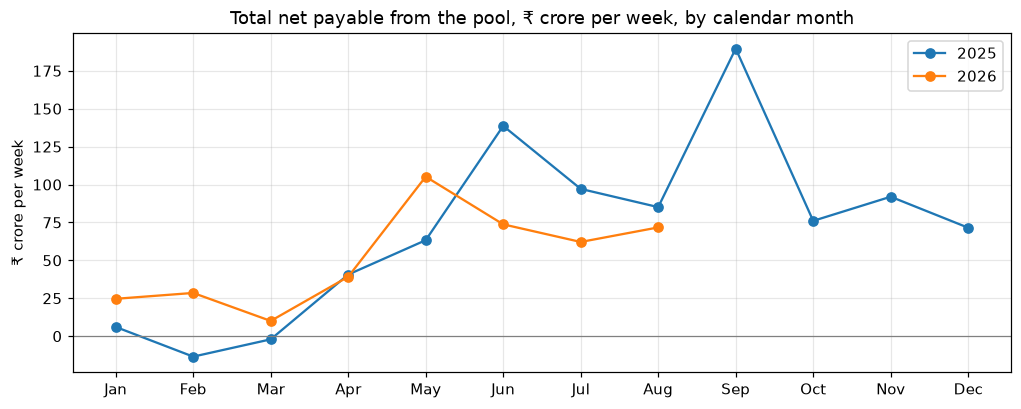

,total_crore,weeks,crore_per_week
cal_year,,,
2025,1827.88,35,52.23
2026,1786.57,35,51.04


,2025 ₹ crore/week,2026 ₹ crore/week,change,change %
cal_month,,,,
1,6.086,24.641,18.555,3.049
2,-13.487,28.510,41.997,-3.114
3,-2.080,10.052,12.132,-5.832
4,40.644,39.172,-1.472,-0.036
5,63.294,105.178,41.884,0.662
6,138.660,73.751,-64.909,-0.468
7,97.125,62.128,-34.997,-0.360
8,85.103,71.724,-13.379,-0.157


In [27]:
season = weekly.assign(cal_year=weekly["month"].str[:4].astype(int), cal_month=weekly["month"].str[5:7].astype(int))
pw = season.groupby(["cal_year", "cal_month"])[TOTAL].agg(total_crore="sum", weeks="size")
pw["crore_per_week"] = pw["total_crore"] / pw["weeks"]
T_Q6_MONTH = save_tab(pw.reset_index(), "09_q6_monthly_per_week.csv")
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(11, 4))
for yr, d in pw.groupby(level="cal_year"):
    d = d.droplevel("cal_year")
    ax.plot(d.index, d["crore_per_week"], "o-", label=str(yr))
ax.set_xticks(range(1, 13), MONTHS); ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("₹ crore per week"); ax.legend()
ax.set_title("Total net payable from the pool, ₹ crore per week, by calendar month")
F_Q6_MONTH = save_fig(fig, "09_q6_monthly_per_week.png")
jan_aug = pw["crore_per_week"].unstack("cal_year").loc[1:8]
jan_aug.columns = [f"{c} ₹ crore/week" for c in jan_aug.columns]
jan_aug["change"] = jan_aug.iloc[:, 1] - jan_aug.iloc[:, 0]
jan_aug["change %"] = jan_aug["change"] / jan_aug.iloc[:, 0]
ja = pw.loc[(slice(None), slice(1, 8)), :].groupby(level="cal_year")[["total_crore", "weeks"]].sum()
ja["crore_per_week"] = ja["total_crore"] / ja["weeks"]
T_Q6_JANAUG = save_tab(jan_aug.reset_index(names="month"), "09_q6_jan_aug_comparison.csv")
display(ja.round(2))
jan_aug.round(3)

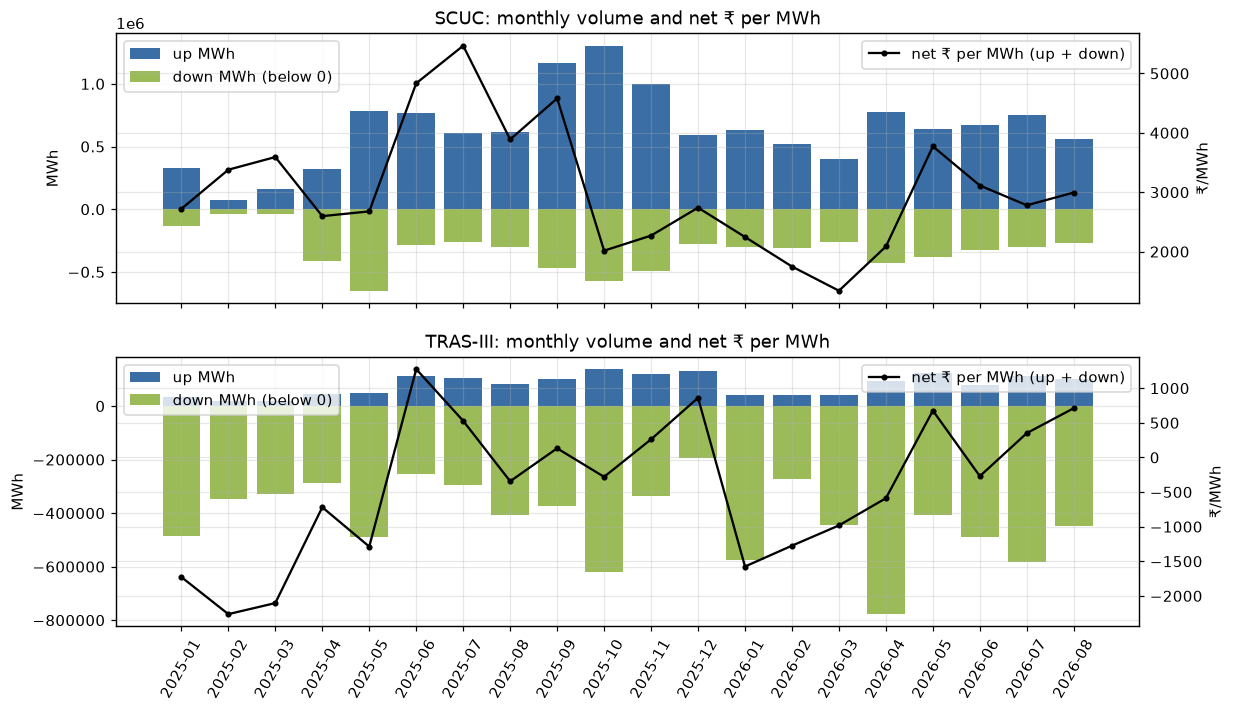

,month,up_mwh,down_mwh,net_crore,net_rs_per_mwh,mechanism
0,2025-01,331165.67,131935.62,125.98,2720.34,SCUC
1,2025-02,69753.56,35024.37,35.40,3378.95,SCUC
2,2025-03,159493.52,37878.35,70.90,3592.14,SCUC
3,2025-04,324376.32,411680.90,191.18,2597.30,SCUC
4,2025-05,787067.78,649863.79,384.71,2677.31,SCUC
5,2025-06,766091.70,287142.22,509.12,4833.84,SCUC
6,2025-07,606250.21,262189.41,474.72,5466.38,SCUC
7,2025-08,616535.72,297843.71,355.58,3888.77,SCUC
8,2025-09,1165421.53,464940.88,746.64,4579.62,SCUC
9,2025-10,1304059.97,570897.59,377.99,2015.97,SCUC


In [28]:
vol = []
for m, label in (("SCUC", "SCUC"), ("TRAS_III_TOTAL", "TRAS-III")):
    d = season.groupby("month").agg(up_mwh=(f"{m}_up_mwh", "sum"), down_mwh=(f"{m}_down_mwh", "sum"),
                                    net_crore=(f"{m}_net_crore", "sum"))
    d["net_rs_per_mwh"] = d["net_crore"] * CRORE / (d["up_mwh"] + d["down_mwh"])
    vol.append(d.assign(mechanism=label))
vol = pd.concat(vol).reset_index()
T_Q6_VOL = save_tab(vol, "09_q6_volume_vs_cost.csv")
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, m in zip(axes, ["SCUC", "TRAS-III"]):
    d = vol[vol["mechanism"] == m]
    ax.bar(d["month"], d["up_mwh"], color="#3b6ea5", label="up MWh")
    ax.bar(d["month"], -d["down_mwh"], color="#9bbb59", label="down MWh (below 0)")
    ax2 = ax.twinx(); ax2.plot(d["month"], d["net_rs_per_mwh"], "k.-", label="net ₹ per MWh (up + down)")
    ax.set_ylabel("MWh"); ax2.set_ylabel("₹/MWh"); ax.set_title(f"{m}: monthly volume and net ₹ per MWh")
    ax.legend(loc="upper left"); ax2.legend(loc="upper right")
axes[1].tick_params(axis="x", rotation=60)
F_Q6_VOL = save_fig(fig, "09_q6_volume_vs_cost.png")
vol.round(2)

Net ₹ per MWh = the month's net amount ÷ (up MWh + down MWh) for that mechanism.

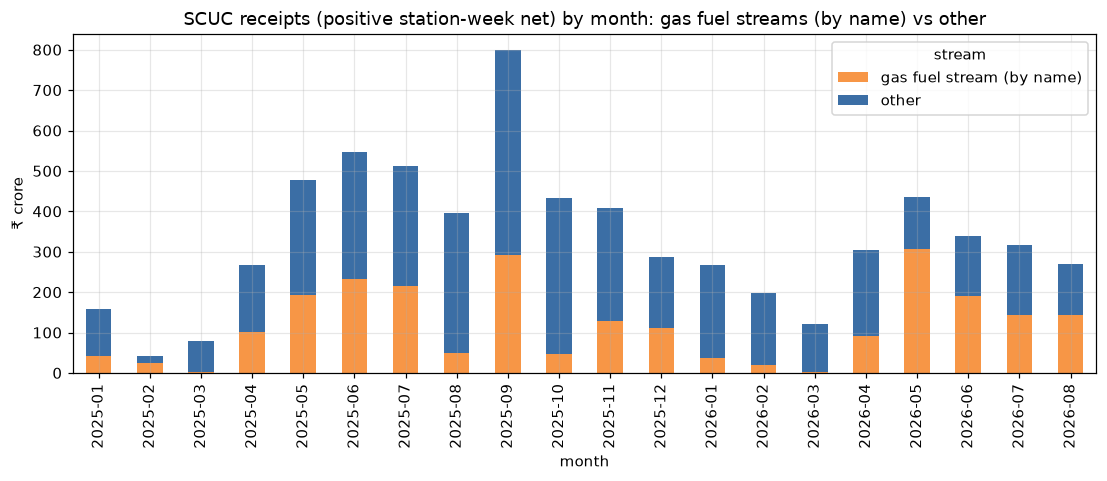

stream,gas fuel stream (by name),other,gas share
month,,,
2025-01,40.81,117.84,0.26
2025-02,24.91,15.76,0.61
2025-03,1.81,76.24,0.02
2025-04,101.49,165.74,0.38
2025-05,191.72,284.98,0.40
2025-06,231.25,316.63,0.42
2025-07,214.88,298.25,0.42
2025-08,49.23,347.24,0.12
2025-09,291.95,506.75,0.37


In [29]:
scw = facts_df[(facts_df["mechanism"] == "SCUC") & (facts_df["measure"] == "net_amount")].assign(
    stream=lambda d: d["station_id"].map(stream_of))
gm = (scw[scw["value"] > 0].groupby(["month", "stream"])["value"].sum().div(CRORE).unstack("stream").fillna(0))
gm["gas share"] = gm["gas fuel stream (by name)"] / gm.sum(axis=1)
T_Q6_GAS = save_tab(gm.reset_index(), "09_q6_gas_vs_other_receipts_by_month.csv")
fig, ax = plt.subplots(figsize=(12, 4))
gm[["gas fuel stream (by name)", "other"]].plot.bar(ax=ax, stacked=True, color=["#f79646", "#3b6ea5"])
ax.set_ylabel("₹ crore"); ax.set_title("SCUC receipts (positive station-week net) by month: gas fuel streams (by name) vs other")
F_Q6_GAS = save_fig(fig, "09_q6_gas_vs_other_receipts.png")
gm.round(2)

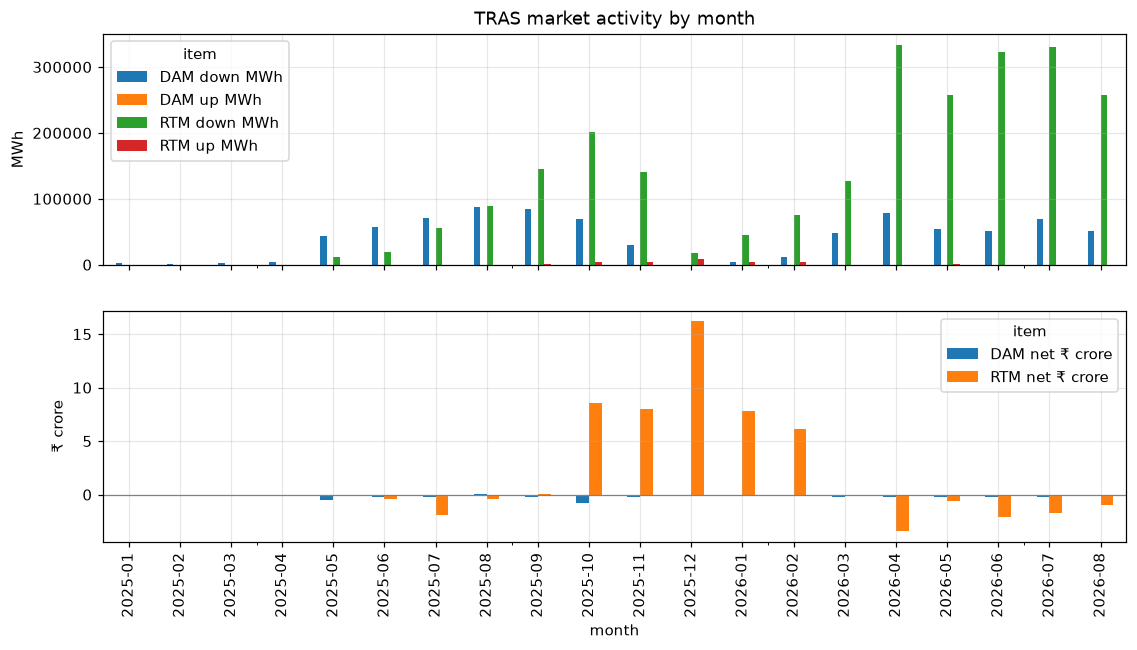

item,DAM down MWh,DAM net ₹ crore,DAM up MWh,RTM down MWh,RTM net ₹ crore,RTM up MWh
month,,,,,,
2025-01,3236.82,-0.06,0.0,0.00,0.00,0.00
2025-02,425.27,-0.01,0.0,0.00,0.00,0.00
2025-03,3150.51,-0.06,0.0,0.00,0.00,0.00
2025-04,3670.00,-0.05,0.0,0.00,0.00,0.00
2025-05,43603.86,-0.49,8.8,11887.36,-0.14,0.00
2025-06,57528.84,-0.21,121.5,18946.05,-0.38,5.25
2025-07,70340.80,-0.27,0.0,55372.95,-1.90,0.00
2025-08,88310.59,0.02,324.6,88550.09,-0.43,10.00
2025-09,84234.70,-0.25,34.5,145719.98,0.08,400.41


In [30]:
mkm = (mk[mk["measure"].isin(["energy_mwh", "net_amount"])]
       .assign(item=lambda d: d["mechanism"].str.replace("TRAS_MARKET_", "") + " " + d["direction"].fillna("net").replace("", "net")
               + " " + d["measure"])
       .pivot_table(index="month", columns="item", values="value", aggfunc="sum").fillna(0))
for c in [c for c in mkm.columns if c.endswith("net_amount")]:
    mkm[c] = mkm[c] / CRORE
mkm = mkm.rename(columns=lambda c: c.replace("net net_amount", "net ₹ crore").replace("energy_mwh", "MWh"))
T_Q6_MKT = save_tab(mkm.reset_index(), "09_q6_market_by_month.csv")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
mkm[[c for c in mkm.columns if "MWh" in c]].plot.bar(ax=a1); a1.set_ylabel("MWh"); a1.set_title("TRAS market activity by month")
mkm[[c for c in mkm.columns if "₹" in c]].plot.bar(ax=a2); a2.set_ylabel("₹ crore"); a2.axhline(0, color="grey", lw=0.8)
F_Q6_MKT = save_fig(fig, "09_q6_market_by_month.png")
mkm.round(2)

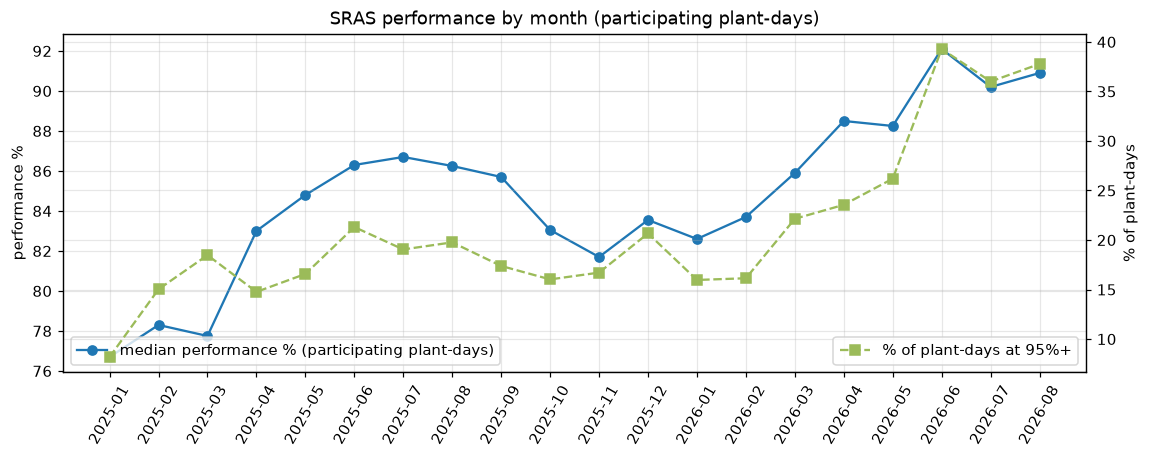

,plant_days,median_pct,share_95_plus,share_below_20
month,,,,
2025-01,525,76.70,0.082,0.030
2025-02,406,78.30,0.150,0.039
2025-03,406,77.75,0.185,0.039
2025-04,420,83.00,0.148,0.026
2025-05,525,84.80,0.166,0.010
2025-06,413,86.30,0.213,0.034
2025-07,525,86.70,0.190,0.023
2025-08,420,86.25,0.198,0.010
2025-09,420,85.70,0.174,0.026


In [31]:
part_m = part.assign(month=part["week_start"].map(dict(zip(weekly["week_start"], weekly["month"]))))
sm = part_m.groupby("month")["performance_pct"].agg(plant_days="size", median_pct="median",
                                                    share_95_plus=lambda s: (s >= 95).mean(),
                                                    share_below_20=lambda s: (s < 20).mean())
T_Q6_SRAS = save_tab(sm.reset_index(), "09_q6_sras_performance_by_month.csv")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sm.index, sm["median_pct"], "o-", label="median performance % (participating plant-days)")
ax2 = ax.twinx(); ax2.plot(sm.index, sm["share_95_plus"] * 100, "s--", color="#9bbb59", label="% of plant-days at 95%+")
ax.set_ylabel("performance %"); ax2.set_ylabel("% of plant-days"); ax.tick_params(axis="x", rotation=60)
ax.legend(loc="lower left"); ax2.legend(loc="lower right"); ax.set_title("SRAS performance by month (participating plant-days)")
F_Q6_SRAS = save_fig(fig, "09_q6_sras_performance_by_month.png")
sm.round(3)

### What the data shows

In [32]:
top_m = pw["crore_per_week"].idxmax(); low_m = pw["crore_per_week"].idxmin()
up_months = int((jan_aug["change"] > 0).sum())
sv, tv = vol[vol["mechanism"] == "SCUC"], vol[vol["mechanism"] == "TRAS-III"]
facts([
    f"Highest month per week: {MONTHS[top_m[1] - 1]} {top_m[0]} ({cr(pw.loc[top_m, 'crore_per_week'])} per week); lowest: "
    f"{MONTHS[low_m[1] - 1]} {low_m[0]} ({cr(pw.loc[low_m, 'crore_per_week'])} per week) ({T_Q6_MONTH}, {F_Q6_MONTH}).",
    f"January–August: 2025 {cr(ja.at[2025, 'crore_per_week'])} per week over {int(ja.at[2025, 'weeks'])} weeks; 2026 "
    f"{cr(ja.at[2026, 'crore_per_week'])} per week over {int(ja.at[2026, 'weeks'])} weeks ({T_Q6_JANAUG}).",
    f"Same-month comparison (Jan–Aug): 2026 was higher per week than 2025 in {up_months} of 8 months ({T_Q6_JANAUG}).",
    f"SCUC net ₹ per MWh (up + down) by month ranged from ₹{sv['net_rs_per_mwh'].min():,.0f} to ₹{sv['net_rs_per_mwh'].max():,.0f}; "
    f"TRAS-III from ₹{tv['net_rs_per_mwh'].min():,.0f} to ₹{tv['net_rs_per_mwh'].max():,.0f} ({T_Q6_VOL}, {F_Q6_VOL}).",
    f"Gas fuel streams' (by name) share of monthly SCUC receipts ranged from {gm['gas share'].min():.1%} to "
    f"{gm['gas share'].max():.1%} ({T_Q6_GAS}).",
    f"Months with RTM TRAS-Down scheduled energy above zero: {int((mkm['RTM down MWh'] > 0).sum())} of {len(mkm)}; "
    f"DAM: {int((mkm['DAM down MWh'] > 0).sum())} of {len(mkm)} ({T_Q6_MKT}).",
    f"SRAS median performance (participating plant-days) by month ranged from {sm['median_pct'].min():.1f}% to "
    f"{sm['median_pct'].max():.1f}% ({T_Q6_SRAS}, {F_Q6_SRAS}).",
])
key("Q6", "Jan–Aug ₹ crore per week, 2025", round(ja.at[2025, "crore_per_week"], 2), "₹ crore/week", T_Q6_JANAUG)
key("Q6", "Jan–Aug ₹ crore per week, 2026", round(ja.at[2026, "crore_per_week"], 2), "₹ crore/week", T_Q6_JANAUG)
key("Q6", f"Highest month per week ({MONTHS[top_m[1] - 1]} {top_m[0]})", round(pw.loc[top_m, "crore_per_week"], 2), "₹ crore/week", T_Q6_MONTH)
key("Q6", "Jan–Aug months where 2026 was higher than 2025", up_months, "months of 8", T_Q6_JANAUG)

- Highest month per week: Sep 2025 (₹189.63 crore per week); lowest: Feb 2025 (₹-13.49 crore per week) (outputs/tables/09_q6_monthly_per_week.csv, outputs/figures/09_q6_monthly_per_week.png).
- January–August: 2025 ₹52.23 crore per week over 35 weeks; 2026 ₹51.04 crore per week over 35 weeks (outputs/tables/09_q6_jan_aug_comparison.csv).
- Same-month comparison (Jan–Aug): 2026 was higher per week than 2025 in 4 of 8 months (outputs/tables/09_q6_jan_aug_comparison.csv).
- SCUC net ₹ per MWh (up + down) by month ranged from ₹1,342 to ₹5,466; TRAS-III from ₹-2,263 to ₹1,275 (outputs/tables/09_q6_volume_vs_cost.csv, outputs/figures/09_q6_volume_vs_cost.png).
- Gas fuel streams' (by name) share of monthly SCUC receipts ranged from 1.1% to 70.8% (outputs/tables/09_q6_gas_vs_other_receipts_by_month.csv).
- Months with RTM TRAS-Down scheduled energy above zero: 16 of 20; DAM: 19 of 20 (outputs/tables/09_q6_market_by_month.csv).
- SRAS median performance (participating plant-days) by month ranged from 76.7% to 92.1% (outputs/tables/09_q6_sras_performance_by_month.csv, outputs/figures/09_q6_sras_performance_by_month.png).

### Questions to interpret

- Why is September 2025 the highest month per week, and why are February and March 2025 negative
  (`09_q6_monthly_per_week.csv`)? (Change % in `09_q6_jan_aug_comparison.csv` is not meaningful for months with a
  negative 2025 base.)
- Why is January–April higher per week in 2026 than in 2025, but June–August lower, while the January–August
  averages are almost equal (₹52.23 vs ₹51.04 crore per week, `09_q6_jan_aug_comparison.csv`)?
- Why does SCUC's net ₹ per MWh vary from about ₹1,342 to ₹5,466 between months, and why does TRAS-III's change sign
  (`09_q6_volume_vs_cost.csv`)?
- Why does the gas fuel streams' share of monthly SCUC receipts range from 1.1% to 70.8%, and in which months is it
  high (`09_q6_gas_vs_other_receipts_by_month.csv`)?
- Is there a seasonal pattern in TRAS market activity or in SRAS median performance (76.7%–92.1% by month)
  (`09_q6_market_by_month.csv`, `09_q6_sras_performance_by_month.csv`)?

## Key numbers

In [33]:
key_numbers = pd.DataFrame(KEY)
key_numbers.to_csv(TAB / "09_key_numbers.csv", index=False)
print("saved outputs/tables/09_key_numbers.csv")
key_numbers

saved outputs/tables/09_key_numbers.csv


,question,metric,value,unit,source
0,Q1,"Total net payable from pool, CY2025",3620.55,₹ crore,outputs/tables/09_q1_year_comparison.csv
1,Q1,"Total net payable from pool, CY2026 to Aug",1786.57,₹ crore,outputs/tables/09_q1_year_comparison.csv
2,Q1,"Weekly average, CY2025",69.63,₹ crore/week,outputs/tables/09_q1_year_comparison.csv
3,Q1,"Weekly average, CY2026 to Aug",51.04,₹ crore/week,outputs/tables/09_q1_year_comparison.csv
4,Q1,Highest week (2025-06-09),270.03,₹ crore,outputs/tables/09_q1_highest_lowest_weeks.csv
5,Q1,Weeks the pool paid out / received,75 / 12,weeks,outputs/tables/09_q1_year_comparison.csv
6,Q2,"SCUC share of total net, CY2025",106.3,%,outputs/tables/09_q2_mechanism_share_by_year.csv
7,Q2,"TRAS-III total net, CY2025",-262.54,₹ crore,outputs/tables/09_q2_mechanism_share_by_year.csv
8,Q2,"SCUC share of total net, CY2026 to Aug",107.9,%,outputs/tables/09_q2_mechanism_share_by_year.csv
9,Q2,"TRAS-III total net, CY2026 to Aug",-151.78,₹ crore,outputs/tables/09_q2_mechanism_share_by_year.csv
